# 2. Propiedades usadas de Moscú

Flujo único desde `PropUsadas_Integrado.csv`, sin reconstruir JOIN ni leer otras entradas. Se conservan las etapas para auditoría. Tukey y las primeras transformaciones se mantienen como análisis histórico de la muestra filtrada; para la segmentación vigente se reincorporan exclusivamente los precios extremos descartados por Tukey. Las exclusiones por calidad no se revierten. No se entrenan modelos ni se aplica clustering.

## 1. Carga y exploración inicial del dataset

`price_rub` representa el precio de venta en RUB. Se muestran dimensiones, esquema y una vista breve. La ruta permite ejecutar desde la raíz o desde la carpeta del notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
COLOR = "#287C8E"
pd.set_option("display.max_columns", 45)

candidatas = [p / rel for p in (Path.cwd(), *Path.cwd().parents)
              for rel in ("data/PropUsadas_Integrado.csv",
                          "Ventas/Fase1_PropUsadas/data/PropUsadas_Integrado.csv")]
ruta_csv = next((p for p in candidatas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError("No se encontró PropUsadas_Integrado.csv dentro del proyecto.")
df_original = pd.read_csv(ruta_csv)
if "price_rub" not in df_original.columns:
    raise ValueError("Falta la variable objetivo price_rub.")
print(f"Entrada: {ruta_csv.name} | Dimensiones: {df_original.shape}")
display(df_original.dtypes.rename("tipo").to_frame())
display(df_original.head(3))

Entrada: PropUsadas_Integrado.csv | Dimensiones: (50000, 40)


,tipo
id,str
date_posted,str
district,str
okrug,str
lat,float64
lon,float64
total_area,float64
living_area,float64
kitchen_area,float64
rooms,int64


,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,building_type,ceiling_height,has_balcony,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type,date_posted_dt,year_month,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
0,S000598,2020-01-01,Yuzhnoye Medvedkovo,SVAO,55.88118,37.61556,99.6,67.9,15.5,4,3,17,1971,khrushchev,2.5,False,designer,Sviblovo,Kaluzhsko-Rizhskaya,34,transport,14.16,11678000,117200,8.5,agency,2020-01-01,2020-01,182500,187100,NaN,NaN,160,19,6.0,8.5,55.8542,37.6532,1978,11.34
1,S001135,2020-01-01,Danilovsky,YuAO,55.71673,37.65142,76.1,45.6,13.9,2,5,9,2011,modern_panel,2.7,False,cosmetic,Tulskaya,Serpukhovsko-Timiryazevskaya,15,walk,4.56,13501000,177400,8.5,agency,2020-01-01,2020-01,234600,252000,NaN,NaN,39,37,6.0,8.5,55.7102,37.6228,1983,4.86
2,S005517,2020-01-01,Chertanovo Tsentralnoye,YuAO,55.62661,37.62812,87.1,54.8,7.1,3,9,17,2004,modern_panel,2.7,False,no_renovation,Sevastopolskaya,Serpukhovsko-Timiryazevskaya,32,transport,14.16,6733000,77300,8.5,agency,2020-01-01,2020-01,177900,198800,NaN,NaN,180,42,6.0,8.5,55.6553,37.6035,1983,11.02


## 2. Limpieza y corrección de inconsistencias

Se verifica el esquema numérico, convirtiendo textos inválidos e infinitos en nulos. Se eliminan duplicados exactos y precios faltantes o no positivos, sin imputar el objetivo. Se corrige exclusivamente `total_area` cuando las tres superficies son finitas y positivas y el total es menor que sala más cocina.

Pisos y años deben ser enteros: pisos positivos, piso no superior al total válido y año de construcción de cuatro cifras (≥1000) no posterior al anuncio. Los valores inválidos pasan a nulos; si piso supera el total válido, se anula el piso. La fecha del anuncio usa `date_posted_dt` con respaldo en `date_posted`; sin fecha válida se detiene el flujo para revisión.

In [2]:
columnas_numericas = [
    "lat", "lon", "total_area", "living_area", "kitchen_area", "rooms",
    "floor", "total_floors", "building_year", "ceiling_height",
    "metro_distance_min", "to_center_km", "price_rub", "price_per_sqm",
    "mortgage_rate_at_listing", "secondary_price_per_sqm", "newbuild_price_per_sqm",
    "secondary_mom_change_pct", "newbuild_mom_change_pct", "n_listings_secondary",
    "n_listings_newbuild", "cbr_key_rate_pct", "avg_mortgage_rate_pct",
    "metro_lat", "metro_lon", "metro_year_opened", "metro_to_center_km"
]

if set(columnas_numericas) - set(df_original):
    raise ValueError("Faltan columnas del esquema numérico integrado.")
df_tipado = df_original.copy(deep=True)
auditoria_tipos = []
for col in columnas_numericas:
    previa = df_tipado[col]
    numerica = pd.to_numeric(previa, errors="coerce")
    auditoria_tipos.append({"variable": col,
        "no_convertibles": int((previa.notna() & numerica.isna()).sum()),
        "infinitos": int(np.isinf(numerica).sum())})
    df_tipado[col] = numerica.replace([np.inf, -np.inf], np.nan)
auditoria_tipos = pd.DataFrame(auditoria_tipos).set_index("variable")
print("Problemas de conversión numérica:")
display(auditoria_tipos.loc[auditoria_tipos.sum(axis=1).gt(0)])
df_unicos = df_tipado.drop_duplicates().copy()
precio_invalido = df_unicos.price_rub.isna() | df_unicos.price_rub.le(0)
df_precio_invalido = df_unicos.loc[precio_invalido].copy()
df_limpio = df_unicos.loc[~precio_invalido].copy()
if df_limpio.empty:
    raise ValueError("No quedan precios válidos.")
display(pd.Series({"Filas originales": len(df_original),
    "Duplicados eliminados": len(df_tipado) - len(df_unicos),
    "Precios inválidos eliminados": int(precio_invalido.sum()),
    "Filas tras limpieza inicial": len(df_limpio)}, name="observaciones").to_frame())

Problemas de conversión numérica:


,no_convertibles,infinitos
variable,,


,observaciones
Filas originales,50000
Duplicados eliminados,0
Precios inválidos eliminados,0
Filas tras limpieza inicial,50000


In [3]:
df_preparacion_base = df_limpio.copy(deep=True)
assert len(df_preparacion_base) == len(df_limpio)
assert df_preparacion_base.index.equals(df_limpio.index)
columnas_precio = ["price_rub"]
precios_referencia = df_preparacion_base[columnas_precio].copy(deep=True)
superficies = df_preparacion_base[["total_area", "living_area", "kitchen_area"]]
superficies_validas = (np.isfinite(superficies) & superficies.gt(0)).all(axis=1)
suma_superficies = superficies.living_area + superficies.kitchen_area
corregir_superficie = superficies_validas & superficies.total_area.lt(suma_superficies)
df_superficies = df_preparacion_base.copy(deep=True)
df_superficies.loc[corregir_superficie, "total_area"] = suma_superficies.loc[corregir_superficie]
ejemplos_superficies = superficies.loc[corregir_superficie].rename(columns={"total_area": "total_area_antes"}).copy()
ejemplos_superficies["total_area_despues"] = df_superficies.loc[corregir_superficie, "total_area"]
print(f"Registros corregidos: {corregir_superficie.sum():,}")
print("Registros no contrastables por superficies inválidas:", (~superficies_validas).sum())
display(ejemplos_superficies.head(3))
pd.testing.assert_frame_equal(df_superficies[["living_area", "kitchen_area"]],
                              df_preparacion_base[["living_area", "kitchen_area"]])
pd.testing.assert_series_equal(df_superficies.loc[~corregir_superficie, "total_area"],
                               df_preparacion_base.loc[~corregir_superficie, "total_area"])

df_validado = df_superficies.copy(deep=True)
fechas_anuncio = pd.to_datetime(df_validado["date_posted_dt"], errors="coerce").fillna(
    pd.to_datetime(df_validado["date_posted"], errors="coerce"))
if fechas_anuncio.isna().any():
    raise ValueError("Hay anuncios sin fecha válida: revisar antes de validar los años.")
anio_anuncio = fechas_anuncio.dt.year
f = df_validado.floor
t = df_validado.total_floors
y = df_validado.building_year
total_valido = np.isfinite(t) & t.gt(0) & t.mod(1).eq(0)
piso_valido = np.isfinite(f) & f.gt(0) & f.mod(1).eq(0)
invalidos_validacion = {
    "total_floors": t.notna() & ~total_valido,
    "floor": f.notna() & (~piso_valido | (total_valido & f.gt(t))),
    "building_year": y.notna() & (~np.isfinite(y) | y.mod(1).ne(0) | y.lt(1000) | y.gt(anio_anuncio))
}
resumen_validacion = []
for col, mascara in invalidos_validacion.items():
    resumen_validacion.append({"variable": col, "nulos_previos": int(df_validado[col].isna().sum()),
                               "inconsistencias_detectadas": int(mascara.sum()),
                               "convertidos_a_nulo": int(mascara.sum())})
    df_validado.loc[mascara, col] = np.nan
display(pd.DataFrame(resumen_validacion).set_index("variable"))
ejemplos_anios = df_superficies.loc[invalidos_validacion["building_year"], ["building_year", "date_posted_dt"]].copy()
ejemplos_anios["building_year_validado"] = df_validado.loc[ejemplos_anios.index, "building_year"]
display(ejemplos_anios.head(3))

Registros corregidos: 247
Registros no contrastables por superficies inválidas: 0


,total_area_antes,living_area,kitchen_area,total_area_despues
27,26.1,17.0,11.3,28.3
54,46.9,32.3,15.1,47.4
289,40.4,27.9,12.7,40.6


,nulos_previos,inconsistencias_detectadas,convertidos_a_nulo
variable,,,
total_floors,0,0,0
floor,0,0,0
building_year,0,1271,1271


,building_year,date_posted_dt,building_year_validado
3,2022,2020-01-01,NaN
18,2023,2020-01-01,NaN
38,2022,2020-01-02,NaN


## 3. Tratamiento de valores faltantes y eliminación de variables

Se imputan numéricas con su mediana, excepto `secondary_mom_change_pct`, que usa la media. Las binarias booleanas o codificadas 0/1 usan la moda y conservan su codificación; las nominales usan `__FALTANTE__`, incluso si tienen solo dos categorías textuales. Un parámetro no estimable detiene el flujo. Se conservan los valores observados y se verifican nuevamente pisos y años.

Los parámetros se estiman sobre la base válida **previa a Tukey**, siguiendo el orden definitivo. Pueden diferir de los del flujo anterior, que imputaba sobre la muestra ya filtrada. La tabla resume solo variables que requieren imputación; el registro completo queda en `resumen_imputacion`.

In [4]:
from pandas.api.types import is_bool_dtype, is_numeric_dtype

df_imputado = df_validado.copy(deep=True)
columnas_binarias = [c for c in df_validado if c == "has_balcony" or is_bool_dtype(df_validado[c])
                     or (is_numeric_dtype(df_validado[c]) and df_validado[c].notna().any()
                         and df_validado[c].dropna().isin([0, 1]).all())]
parametros_imputacion = {}
filas_imputacion = []
for col in df_validado:
    serie = df_validado[col]
    nulos = int(serie.isna().sum())
    if col in columnas_binarias:
        estrategia = "Moda (binaria)"
        modas = serie.mode(dropna=True)
        valor = modas.iloc[0] if len(modas) else np.nan
    elif is_numeric_dtype(serie):
        estrategia = "Media aritmética" if col == "secondary_mom_change_pct" else "Mediana"
        valor = serie.mean() if col == "secondary_mom_change_pct" else serie.median()
    else:
        estrategia = "Categoría __FALTANTE__ (nominal)"
        valor = "__FALTANTE__"
    if nulos:
        if pd.isna(valor):
            raise ValueError(f"No se puede estimar el parámetro de imputación de {col}.")
        if isinstance(serie.dtype, pd.CategoricalDtype) and valor not in serie.cat.categories:
            df_imputado[col] = serie.cat.add_categories([valor])
        df_imputado[col] = df_imputado[col].fillna(valor)
        parametros_imputacion[col] = valor
    filas_imputacion.append({"variable": col,
        "nulos_originales_post_Tukey": int(df_preparacion_base[col].isna().sum()),
        "nulos_antes_de_imputar": nulos, "estrategia": estrategia,
        "valor_utilizado": valor if nulos else "No requerido",
        "nulos_restantes": int(df_imputado[col].isna().sum())})
resumen_imputacion = pd.DataFrame(filas_imputacion).set_index("variable")
print("Variables binarias:", columnas_binarias)
display(resumen_imputacion.loc[resumen_imputacion.nulos_antes_de_imputar.gt(0)])
for col in columnas_binarias:
    assert df_imputado[col].isin(df_validado[col].dropna().unique()).all()
    assert df_imputado[col].dtype == df_validado[col].dtype
for col in df_validado:
    pd.testing.assert_series_equal(df_imputado.loc[df_validado[col].notna(), col],
                                   df_validado.loc[df_validado[col].notna(), col])

import re

columnas_new_build = [c for c in df_imputado
                      if "newbuild" in re.sub(r"[^a-z0-9]", "", c.lower())]
columnas_solicitadas = ["avg_mortgage_rate_pct", "cbr_key_rate_pct", "living_area", "rooms", "segmento_ambientes"]
columnas_eliminadas = list(dict.fromkeys(
    [c for c in columnas_solicitadas if c in df_imputado.columns] + columnas_new_build))
df_preparado = df_imputado.drop(columns=columnas_eliminadas, errors="ignore").copy()
print("Columnas eliminadas:")
display(pd.DataFrame({"nombre_exacto": columnas_eliminadas}))

Variables binarias: ['has_balcony']
Columnas eliminadas:


,nulos_originales_post_Tukey,nulos_antes_de_imputar,estrategia,valor_utilizado,nulos_restantes
variable,,,,,
building_year,0,1271,Mediana,1988.0,0
secondary_mom_change_pct,678,678,Media aritmética,0.623706,0
newbuild_mom_change_pct,678,678,Mediana,0.47,0


,nombre_exacto
0,avg_mortgage_rate_pct
1,cbr_key_rate_pct
2,living_area
3,rooms
4,newbuild_price_per_sqm
5,newbuild_mom_change_pct
6,n_listings_newbuild


**Variables descartadas.** `avg_mortgage_rate_pct` se elimina por su relación con tasas hipotecarias y `cbr_key_rate_pct` por representar la tasa del Banco Central de Rusia. `living_area` se elimina después de corregir `total_area`, que se conserva. `rooms` y su derivada `segmento_ambientes` (si existe) se descartan para priorizar la superficie como criterio de segmentación y evitar redundancias entre características relacionadas.

Las variables de construcciones nuevas se detectan por `new_build` o `newbuild`, ignorando separadores. Se eliminan `newbuild_price_per_sqm`, `newbuild_mom_change_pct` y `n_listings_newbuild`, porque el análisis se concentra en propiedades usadas. La lista exacta de columnas presentes eliminadas se muestra arriba.

In [5]:
assert not df_preparado.isna().any().any()
assert np.isfinite(df_preparado.select_dtypes(include="number")).all().all()
assert (df_preparado.floor.gt(0) & df_preparado.total_floors.gt(0)
        & df_preparado.floor.le(df_preparado.total_floors)).all()
assert df_preparado[["floor", "total_floors", "building_year"]].mod(1).eq(0).all().all()
assert (df_preparado.building_year.ge(1000) & df_preparado.building_year.le(anio_anuncio)).all()
assert not set(columnas_solicitadas).intersection(df_preparado)
assert not any("newbuild" in re.sub(r"[^a-z0-9]", "", c.lower()) for c in df_preparado)
pd.testing.assert_series_equal(df_preparado.price_rub, df_limpio.price_rub)
print(f"Base preparada: {df_preparado.shape}; sin nulos pendientes.")

Base preparada: (50000, 33); sin nulos pendientes.


## 4. Análisis histórico de outliers mediante Tukey

Se calcula una sola vez Q1 y Q3 del precio preparado: IQR = Q3 − Q1, límite inferior = Q1 − 1,5 IQR y superior = Q3 + 1,5 IQR. Se conservan ambos límites inclusive; `df_outliers` permite revisar las exclusiones. Los precios extremos pueden corresponder a lujo legítimo: el filtro es exploratorio y cambia la población representada.

Una única figura compara la distribución antes y después del filtro, con histograma/KDE y boxplot. Se usan los mismos intervalos del histograma y se comparte el eje de precio en millones de RUB. Las estadísticas completas se consolidan en la sección siguiente. Los puntos extremos del boxplot posterior no se vuelven a eliminar.

**Resultado histórico:** 47.541 observaciones retenidas y 2.459 apartadas por precio. La sección 6 revierte únicamente esta exclusión exploratoria; no vuelve a calcular los límites de precio.

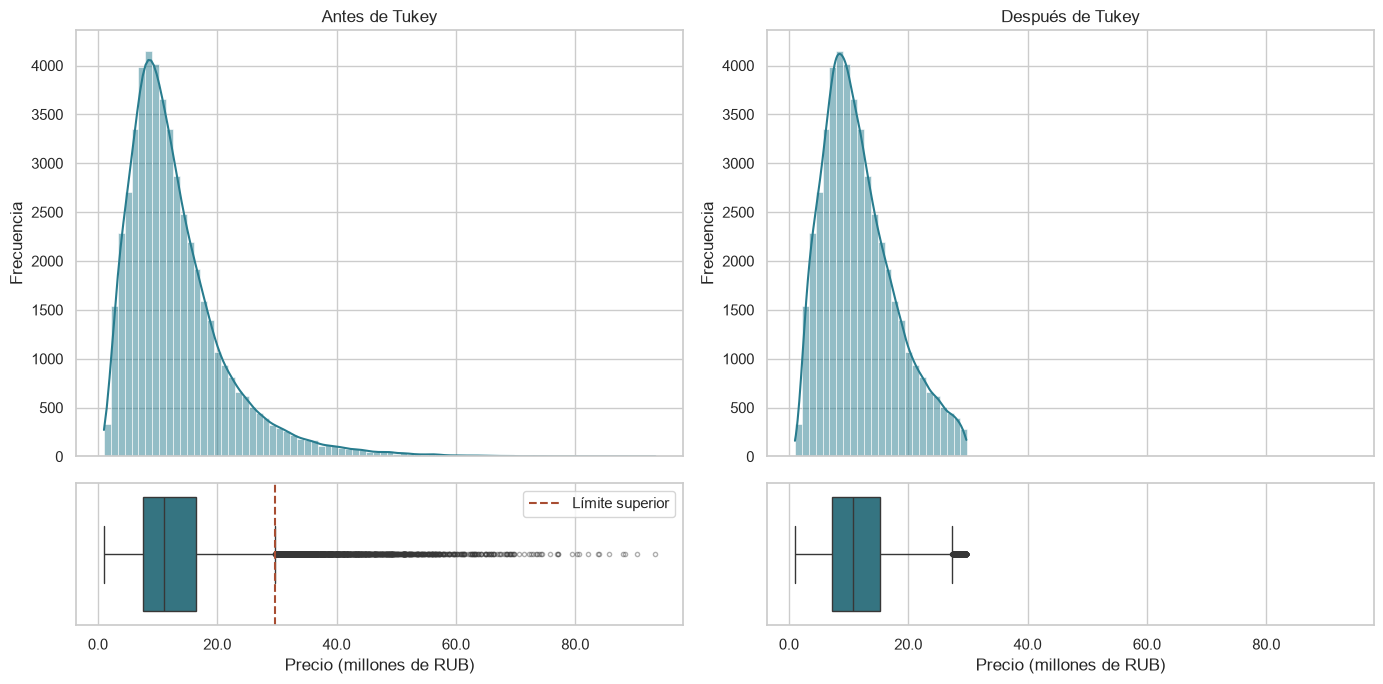

,Tukey único
Q1 (RUB),7.481750e+06
Q3 (RUB),1.638725e+07
IQR (RUB),8.905500e+06
Límite inferior (RUB),-5.876500e+06
Límite superior (RUB),2.974550e+07
Observaciones excluidas,2.459000e+03
Porcentaje excluido,4.918000e+00
Observaciones retenidas,4.754100e+04


In [6]:
q1_precio, q3_precio = df_preparado.price_rub.quantile([0.25, 0.75])
iqr_precio = q3_precio - q1_precio
limite_inferior = q1_precio - 1.5 * iqr_precio
limite_superior = q3_precio + 1.5 * iqr_precio
mascara_dentro = df_preparado.price_rub.between(limite_inferior, limite_superior)
df_outliers = df_preparado.loc[~mascara_dentro].copy()
df_sin_outliers = df_preparado.loc[mascara_dentro].copy()
assert len(df_sin_outliers) == 47_541
assert len(df_preparado) == len(df_sin_outliers) + len(df_outliers)
display(pd.Series({"Q1 (RUB)": q1_precio, "Q3 (RUB)": q3_precio, "IQR (RUB)": iqr_precio,
    "Límite inferior (RUB)": limite_inferior, "Límite superior (RUB)": limite_superior,
    "Observaciones excluidas": len(df_outliers),
    "Porcentaje excluido": 100 * len(df_outliers) / len(df_preparado),
    "Observaciones retenidas": len(df_sin_outliers)}, name="Tukey único").to_frame())
bins_precio = np.linspace(df_preparado.price_rub.min(), df_preparado.price_rub.max(), 81)
formato_millones = FuncFormatter(lambda x, _: f"{x / 1e6:,.1f}")
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
for j, (nombre, datos) in enumerate([("Antes de Tukey", df_preparado), ("Después de Tukey", df_sin_outliers)]):
    sns.histplot(x=datos.price_rub, bins=bins_precio, kde=True, color=COLOR, ax=axes[0, j])
    sns.boxplot(x=datos.price_rub, color=COLOR, showfliers=True, ax=axes[1, j],
                flierprops={"markersize": 3, "alpha": 0.4})
    axes[0, j].set(title=nombre, xlabel="", ylabel="Frecuencia")
    axes[1, j].set(xlabel="Precio (millones de RUB)", ylabel="")
    axes[1, j].xaxis.set_major_formatter(formato_millones)
    if j == 0:
        axes[1, j].axvline(limite_superior, linestyle="--", color="#A84D32", label="Límite superior")
        axes[1, j].legend()
plt.tight_layout()
plt.show()

## 5. Transformaciones históricas del precio: logaritmo y Box-Cox

Sobre los mismos precios positivos posteriores a Tukey se agregan `log_price_rub = ln(price_rub)` y `boxcox_price_rub`. Box-Cox recibe el **precio original**, sin desplazarlo ni estandarizarlo, y estima λ por máxima verosimilitud. No se excluyen filas. `df_transformado` conserva las columnas originales preparadas.

La tabla compara cuatro distribuciones sin repetir resúmenes: precio válido anterior a Tukey, precio retenido, logaritmo y Box-Cox. Ubicación y dispersión usan escalas diferentes; asimetría y curtosis excesiva de Fisher son adimensionales (normal = 0). La desviación estándar es muestral. Las normales de referencia se ajustan con media y desvío observados y no constituyen pruebas de normalidad.

Todas las tablas, curvas y el λ de esta sección corresponden al análisis filtrado de 47.541 observaciones. `df_transformado` se conserva como referencia histórica. Las transformaciones del dataset ampliado se recalculan por separado en la sección 6, incluido un nuevo ajuste de λ.

λ óptimo por máxima verosimilitud: 0.33888833


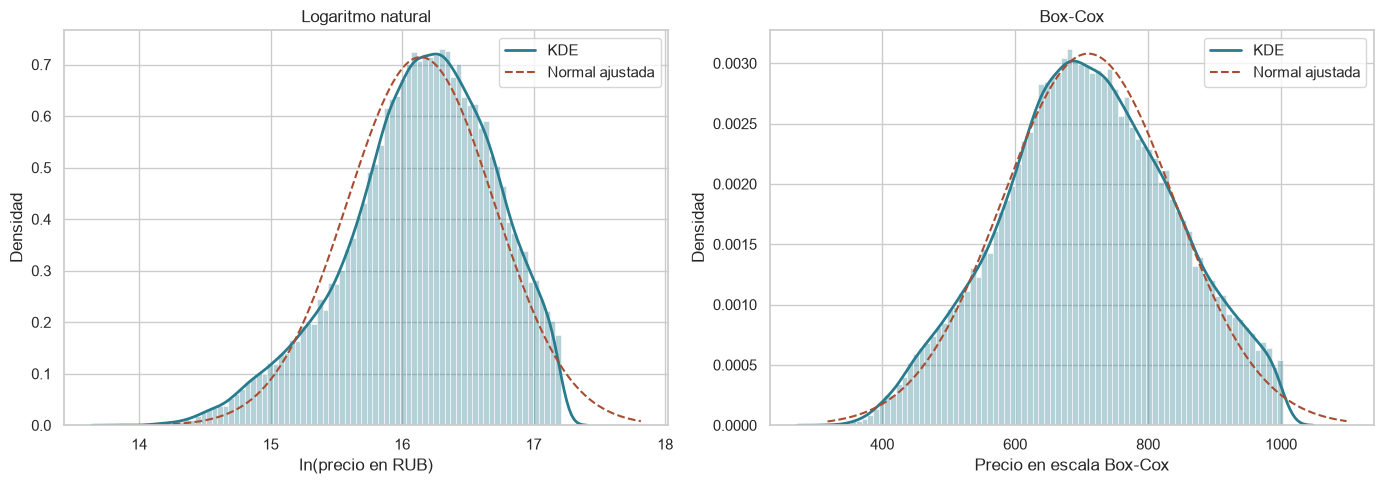

,Precio antes de Tukey (RUB),Precio después de Tukey (RUB),Logaritmo natural,Box-Cox
Cantidad,"50,000.0000","47,541.0000","47,541.0000","47,541.0000"
Media,"13,122,821.5200","11,783,522.6646",16.1404,709.8620
Mediana,"11,086,000.0000","10,689,000.0000",16.1847,708.2105
Desviación estándar,"8,564,072.9834","6,027,160.1338",0.5584,129.5457
Mínimo,"1,019,000.0000","1,019,000.0000",13.8343,317.7082
Máximo,"93,437,000.0000","29,744,000.0000",17.2081,"1,003.0335"
Q1,"7,481,750.0000","7,303,000.0000",15.8038,622.0835
Q3,"16,387,250.0000","15,343,000.0000",16.5462,800.8798
Asimetría,1.9968,0.7411,-0.4956,-0.0283
Curtosis excesiva,6.5578,0.0423,0.0078,-0.4490


In [7]:
from scipy.stats import boxcox, norm

precios = df_sin_outliers.price_rub
if not (np.isfinite(precios) & precios.gt(0)).all() or precios.nunique() < 2:
    raise ValueError("Las transformaciones requieren precios positivos, finitos y no constantes.")
df_transformado = df_sin_outliers.copy(deep=True)
df_transformado["log_price_rub"] = np.log(precios)
valores_boxcox, lambda_optimo = boxcox(precios.to_numpy(dtype=float))
df_transformado["boxcox_price_rub"] = valores_boxcox
print(f"λ óptimo por máxima verosimilitud: {lambda_optimo:.8f}")

def estadisticas(serie):
    return pd.Series({"Cantidad": serie.count(), "Media": serie.mean(), "Mediana": serie.median(),
        "Desviación estándar": serie.std(), "Mínimo": serie.min(), "Máximo": serie.max(),
        "Q1": serie.quantile(0.25), "Q3": serie.quantile(0.75),
        "Asimetría": serie.skew(), "Curtosis excesiva": serie.kurt()})

comparacion_distribuciones = pd.DataFrame({
    "Precio antes de Tukey (RUB)": estadisticas(df_preparado.price_rub),
    "Precio después de Tukey (RUB)": estadisticas(precios),
    "Logaritmo natural": estadisticas(df_transformado.log_price_rub),
    "Box-Cox": estadisticas(df_transformado.boxcox_price_rub)})
display(comparacion_distribuciones.style.format("{:,.4f}").set_properties(
    subset=pd.IndexSlice[["Asimetría", "Curtosis excesiva"], :], **{"font-weight": "bold"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, titulo in zip(axes, ["log_price_rub", "boxcox_price_rub"], ["Logaritmo natural", "Box-Cox"]):
    valores = df_transformado[col]
    media, desvio = valores.mean(), valores.std()
    x = np.linspace(min(valores.min(), media - 3 * desvio), max(valores.max(), media + 3 * desvio), 600)
    sns.histplot(x=valores, bins=80, stat="density", color=COLOR, alpha=0.35, ax=ax)
    sns.kdeplot(x=valores, color=COLOR, linewidth=2, label="KDE", ax=ax)
    ax.plot(x, norm.pdf(x, media, desvio), color="#A84D32", linestyle="--", label="Normal ajustada")
    ax.set(title=titulo, xlabel="ln(precio en RUB)" if col == "log_price_rub" else "Precio en escala Box-Cox",
           ylabel="Densidad")
    ax.legend()
plt.tight_layout()
plt.show()

El precio inicial tiene cola hacia valores altos; Tukey reduce su amplitud. El logaritmo reduce la magnitud de la asimetría e invierte su signo (0,741 → −0,496 en la muestra retenida). Box-Cox, con λ ≈ 0,339, deja la asimetría cerca de cero (−0,028), pero su curtosis excesiva es negativa (−0,449). El centro es aproximadamente acampanado; las colas difieren de la normal, especialmente por el límite superior del filtro. Una mayor simetría no demuestra normalidad ni justifica seguir excluyendo observaciones.

## 6. Reincorporación y segmentación por superficie y okrug

Se decidió reincorporar los outliers globales porque los precios elevados pueden corresponder a propiedades legítimas según su ubicación y superficie. Se recuperan exclusivamente los IDs de `df_outliers` desde `df_preparado`, donde todas las filas ya recibieron las mismas correcciones, validaciones, imputaciones y eliminación de variables **antes** del filtro. Así se conservan los parámetros de limpieza y no se necesitan nuevas lecturas ni imputaciones. No se aplica nuevamente Tukey.

Se exige que `id` sea único y no nulo y que los IDs a reincorporar no se solapen con los retenidos; una anomalía detiene el flujo en lugar de descartar duplicados silenciosamente. `trazabilidad_reincorporacion` identifica cada fila retenida o reincorporada, y `resumen_reincorporacion` concilia las cantidades con las exclusiones previas por calidad.

Los límites de superficie se obtienen una sola vez de la muestra histórica (Q1 = 53,9 m²; Q3 = 76,5 m²) y se congelan para el dataset ampliado: Pequeñas < Q1, Medianas entre Q1 y Q3 inclusive, Grandes > Q3. El orden de los okrugs también se fija según las medianas de la muestra histórica, sin reordenar con los datos reincorporados.

Se recalculan `ln(price_rub)` y Box-Cox **para todo el dataset ampliado**, ajustando un nuevo λ por máxima verosimilitud; el λ histórico se mantiene identificado por separado. El gráfico usa únicamente `price_rub`, los colores originales y el rango completo, mostrando todos los puntos extremos.

Cuartiles de superficie congelados: 53.90 y 76.50 m²
λ histórico filtrado: 0.33888833 | λ reajustado ampliado: 0.07821787


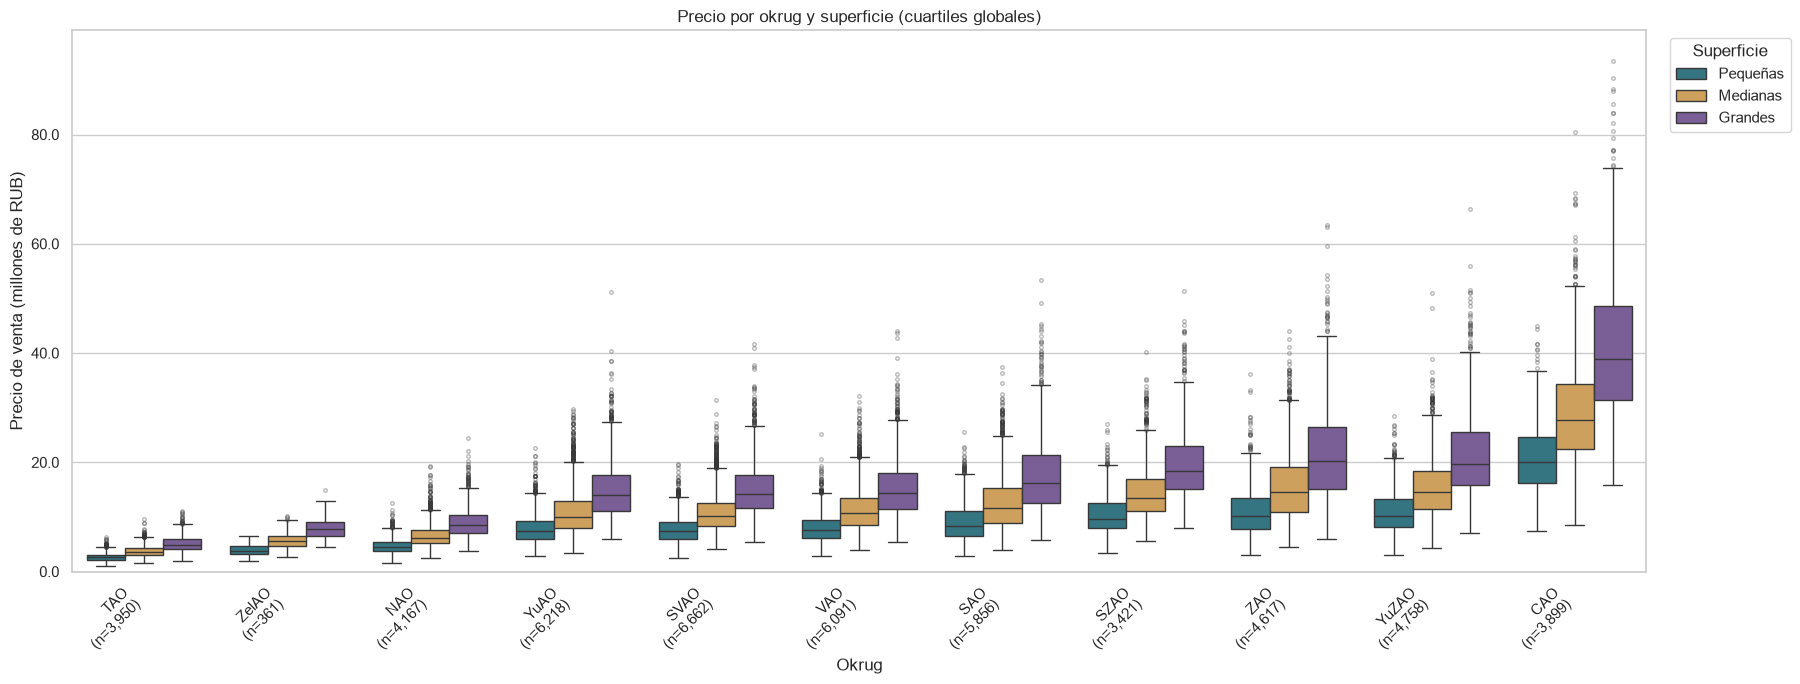

In [8]:
# Referencia histórica: estos cuartiles y este orden no se recalculan con la muestra ampliada.
q1_superficie, q3_superficie = df_sin_outliers.total_area.quantile([0.25, 0.75])
orden_superficie = ["Pequeñas", "Medianas", "Grandes"]
def clasificar_superficie(datos):
    return pd.Categorical(np.select(
        [datos.total_area.lt(q1_superficie), datos.total_area.gt(q3_superficie)],
        ["Pequeñas", "Grandes"], default="Medianas"), categories=orden_superficie, ordered=True)

df_filtrado_segmentado = df_transformado.copy(deep=True)
df_filtrado_segmentado["segmento_superficie"] = clasificar_superficie(df_filtrado_segmentado)
medianas_historicas_okrug = df_sin_outliers.groupby("okrug", observed=True).price_rub.median()
orden_okrug = medianas_historicas_okrug.sort_index().sort_values(kind="stable").index.tolist()

# Recuperar únicamente los IDs apartados por el Tukey histórico, ya preparados de la misma forma.
for nombre, datos in [("base preparada", df_preparado), ("retenidos", df_sin_outliers), ("outliers históricos", df_outliers)]:
    if datos.id.isna().any() or not datos.id.is_unique:
        raise ValueError(f"Se requiere id único y no nulo en {nombre}.")
ids_retenidos = set(df_sin_outliers.id)
ids_reincorporados = set(df_outliers.id)
assert len(ids_reincorporados) == 2_459
assert ids_retenidos.isdisjoint(ids_reincorporados)
assert ids_retenidos | ids_reincorporados == set(df_preparado.id)
df_reincorporados = df_preparado.loc[df_preparado.id.isin(ids_reincorporados)].copy()
pd.testing.assert_frame_equal(df_reincorporados, df_outliers)
pd.testing.assert_series_equal(df_reincorporados.dtypes, df_sin_outliers.dtypes)
df_ampliado_base = pd.concat([df_sin_outliers, df_reincorporados], axis=0).sort_index()
pd.testing.assert_frame_equal(df_ampliado_base, df_preparado)
cantidad_esperada = len(df_original) - (len(df_tipado) - len(df_unicos)) - len(df_precio_invalido)
assert len(df_ampliado_base) == cantidad_esperada
assert df_ampliado_base.id.is_unique

trazabilidad_reincorporacion = df_ampliado_base[["id", "price_rub"]].copy()
trazabilidad_reincorporacion.index.name = "indice_integrado"
trazabilidad_reincorporacion["estado"] = np.where(
    trazabilidad_reincorporacion.id.isin(ids_reincorporados), "Reincorporada por Tukey", "Retenida originalmente")
resumen_reincorporacion = pd.Series({
    "Entrada integrada": len(df_original),
    "Duplicados excluidos por calidad": len(df_tipado) - len(df_unicos),
    "Precios inválidos excluidos por calidad": len(df_precio_invalido),
    "Retenidas tras Tukey histórico": len(df_sin_outliers),
    "Reincorporadas exclusivamente por Tukey": len(df_reincorporados),
    "Total ampliado esperado": cantidad_esperada,
    "Total ampliado observado": len(df_ampliado_base)}, name="observaciones")

# Recalcular las transformaciones sobre toda la muestra ampliada, sin reutilizar el λ histórico.
precios_ampliados = df_ampliado_base.price_rub
assert (np.isfinite(precios_ampliados) & precios_ampliados.gt(0)).all()
df_segmentado = df_ampliado_base.copy(deep=True)
df_segmentado["log_price_rub"] = np.log(precios_ampliados)
boxcox_ampliado, lambda_ampliado = boxcox(precios_ampliados.to_numpy(dtype=float))
df_segmentado["boxcox_price_rub"] = boxcox_ampliado
df_segmentado["segmento_superficie"] = clasificar_superficie(df_segmentado)
assert df_segmentado.columns.equals(df_filtrado_segmentado.columns)
pd.testing.assert_series_equal(df_segmentado.dtypes, df_filtrado_segmentado.dtypes)
pd.testing.assert_series_equal(df_segmentado.loc[df_filtrado_segmentado.index, "segmento_superficie"],
                               df_filtrado_segmentado.segmento_superficie)
print(f"Cuartiles de superficie congelados: {q1_superficie:.2f} y {q3_superficie:.2f} m²")
print(f"λ histórico filtrado: {lambda_optimo:.8f} | λ reajustado ampliado: {lambda_ampliado:.8f}")

resumen_okrug = df_segmentado.groupby("okrug", observed=True).agg(
    cantidad=("price_rub", "size"), precio_mediano_rub=("price_rub", "median")).reindex(orden_okrug)
assert set(orden_okrug) == set(df_segmentado.okrug.unique())
fig, ax = plt.subplots(figsize=(max(16, 1.65 * len(orden_okrug)), 7))
sns.boxplot(data=df_segmentado, x="okrug", y="price_rub", hue="segmento_superficie",
    order=orden_okrug, hue_order=orden_superficie, palette=["#287C8E", "#E0A34B", "#7955A1"],
    showfliers=True, flierprops={"markersize": 2.5, "alpha": 0.35}, ax=ax)
ax.set(title="Precio por okrug y superficie (cuartiles globales)", xlabel="Okrug",
       ylabel="Precio de venta (millones de RUB)", ylim=(0, df_segmentado.price_rub.max() * 1.06))
ax.yaxis.set_major_formatter(formato_millones)
ax.set_xticks(range(len(orden_okrug)))
ax.set_xticklabels([f"{o}\n(n={int(resumen_okrug.loc[o, 'cantidad']):,})" for o in orden_okrug],
                   rotation=45, ha="right")
ax.legend(title="Superficie", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Conciliación de observaciones**

| Etapa | Observaciones |
| --- | --- |
| Entrada integrada | 50.000 |
| Duplicados excluidos por calidad | 0 |
| Precios inválidos excluidos por calidad | 0 |
| Retenidas tras Tukey histórico | 47.541 |
| Reincorporadas exclusivamente por Tukey | 2.459 |
| Total ampliado esperado | 50.000 |
| Total ampliado observado | 50.000 |

## 7. Comparación de resultados y estadísticas de los segmentos

La primera tabla compara los precios del dataset filtrado histórico y del ampliado. La tabla por segmento se actualiza con todas las observaciones y conserva el orden histórico de okrugs y Pequeñas, Medianas, Grandes. Incluye la cantidad reincorporada por combinación para auditar el cambio. Precios y desvíos están en RUB; asimetría y curtosis excesiva son adimensionales y sus estimadores necesitan al menos 3 y 4 observaciones respectivamente.

Se mantienen los indicadores exploratorios: pocas observaciones si n < 100 y dispersión elevada si CV = desvío / media ≥ 0,50. No son reglas universales ni criterios de exclusión. Ninguna medida de forma justifica automáticamente descartar propiedades de precio elevado.

In [9]:
metricas_comparacion = ["Cantidad", "Media", "Mediana", "Desviación estándar", "Mínimo", "Máximo", "Asimetría", "Curtosis excesiva"]
comparacion_reincorporacion = pd.concat([
    estadisticas(df_sin_outliers.price_rub).reindex(metricas_comparacion).rename("Filtrado histórico"),
    estadisticas(df_segmentado.price_rub).reindex(metricas_comparacion).rename("Ampliado vigente")], axis=1)
comparacion_reincorporacion.loc["Observaciones reincorporadas"] = [0, len(df_reincorporados)]

tabla_segmentos = df_segmentado.groupby(["okrug", "segmento_superficie"], observed=False).agg(
    cantidad=("price_rub", "size"), precio_medio_rub=("price_rub", "mean"),
    precio_mediano_rub=("price_rub", "median"), desviacion_estandar_rub=("price_rub", "std"),
    asimetria=("price_rub", "skew"), curtosis_excesiva=("price_rub", lambda s: s.kurt()))
indice_segmentos = pd.MultiIndex.from_product([orden_okrug, orden_superficie],
                                              names=["okrug", "segmento_superficie"])
tabla_segmentos = tabla_segmentos.reindex(indice_segmentos)
conteos_anteriores = df_filtrado_segmentado.groupby(["okrug", "segmento_superficie"], observed=False).size()
conteos_reincorporados = df_segmentado.loc[df_segmentado.id.isin(ids_reincorporados)].groupby(
    ["okrug", "segmento_superficie"], observed=False).size()
tabla_segmentos["cantidad_anterior"] = conteos_anteriores.reindex(indice_segmentos, fill_value=0)
tabla_segmentos["reincorporadas"] = conteos_reincorporados.reindex(indice_segmentos, fill_value=0)
assert (tabla_segmentos.cantidad == tabla_segmentos.cantidad_anterior + tabla_segmentos.reincorporadas).all()
MIN_OBSERVACIONES = 100
UMBRAL_CV = 0.50
tabla_segmentos["coef_variacion"] = tabla_segmentos.desviacion_estandar_rub / tabla_segmentos.precio_medio_rub
tabla_segmentos["pocas_observaciones"] = tabla_segmentos.cantidad.lt(MIN_OBSERVACIONES)
tabla_segmentos["dispersion_elevada"] = tabla_segmentos.coef_variacion.ge(UMBRAL_CV)
tabla_segmentos["forma_estimable"] = tabla_segmentos.cantidad.ge(4)
segmentos_atencion = tabla_segmentos.loc[tabla_segmentos.pocas_observaciones | tabla_segmentos.dispersion_elevada]
print("Combinaciones con pocas observaciones:", int(tabla_segmentos.pocas_observaciones.sum()))
print("Combinaciones con dispersión elevada:", int(tabla_segmentos.dispersion_elevada.sum()))
print("Identificación de combinaciones señaladas:")
for (okrug, superficie), fila in segmentos_atencion.iterrows():
    motivos = []
    if fila.pocas_observaciones: motivos.append(f"n={int(fila.cantidad)} < {MIN_OBSERVACIONES}")
    if fila.dispersion_elevada: motivos.append(f"CV={fila.coef_variacion:.1%}")
    print(f"  {okrug} / {superficie}: {', '.join(motivos)}")

assert len(df_segmentado) == cantidad_esperada == len(df_sin_outliers) + len(df_reincorporados)
assert df_segmentado.id.is_unique
assert df_segmentado.index.equals(df_preparado.index)
pd.testing.assert_frame_equal(df_segmentado[df_preparado.columns], df_preparado)
pd.testing.assert_series_equal(df_segmentado.loc[df_sin_outliers.index, "price_rub"], df_sin_outliers.price_rub)
assert not {"rooms", "segmento_ambientes", "living_area", "avg_mortgage_rate_pct", "cbr_key_rate_pct"}.intersection(df_segmentado)
assert not any("newbuild" in re.sub(r"[^a-z0-9]", "", c.lower()) for c in df_segmentado)
assert not df_segmentado.isna().any().any()
assert np.isfinite(df_segmentado.select_dtypes(include="number")).all().all()
assert tabla_segmentos.cantidad.sum() == len(df_segmentado)
assert tabla_segmentos.reincorporadas.sum() == len(df_reincorporados)
assert (df_segmentado.floor.gt(0) & df_segmentado.total_floors.gt(0) & df_segmentado.floor.le(df_segmentado.total_floors)).all()
assert (df_segmentado.building_year.ge(1000) & df_segmentado.building_year.le(anio_anuncio)).all()
df_final = df_segmentado.copy(deep=True)
trazabilidad = pd.DataFrame([{"etapa": nombre, "filas": len(datos), "columnas": datos.shape[1]}
    for nombre, datos in [("Entrada", df_original), ("Limpieza inicial", df_limpio),
    ("Correcciones e imputación", df_preparado), ("Tukey histórico", df_sin_outliers),
    ("Transformaciones históricas", df_transformado), ("Reincorporadas", df_reincorporados),
    ("Segmentación ampliada vigente", df_final)]])
print(f"Resultado vigente: df_final y df_segmentado con {df_final.shape}.")


Combinaciones con pocas observaciones: 1
Combinaciones con dispersión elevada: 0
Identificación de combinaciones señaladas:
  ZelAO / Pequeñas: n=81 < 100
Resultado vigente: df_final y df_segmentado con (50000, 36).


**Comparación de los precios antes y después de reincorporar**

Precios y desviación estándar en RUB; asimetría y curtosis excesiva sin unidades.

| Métrica | Filtrado histórico | Ampliado vigente |
| --- | ---: | ---: |
| Cantidad | 47.541 | 50.000 |
| Media | 11.783.522,665 | 13.122.821,520 |
| Mediana | 10.689.000,000 | 11.086.000,000 |
| Desviación estándar | 6.027.160,134 | 8.564.072,983 |
| Mínimo | 1.019.000,000 | 1.019.000,000 |
| Máximo | 29.744.000,000 | 93.437.000,000 |
| Asimetría | 0,741 | 1,997 |
| Curtosis excesiva | 0,042 | 6,558 |
| Observaciones reincorporadas | 0 | 2.459 |

**Estadísticas por okrug y superficie — dataset ampliado**

| Okrug | Superficie | Cantidad | Media (RUB) | Mediana (RUB) | Desvío (RUB) | Asimetría | Curtosis excesiva |
| --- | --- | --- | --- | --- | --- | --- | --- |
| TAO | Pequeñas | 943 | 2.686.823,97 | 2.585.000,00 | 782.267,39 | 0,979 | 1,562 |
| TAO | Medianas | 1.935 | 3.734.497,67 | 3.588.000,00 | 1.014.978,75 | 0,914 | 1,472 |
| TAO | Grandes | 1.072 | 5.070.836,75 | 4.865.500,00 | 1.444.951,47 | 0,733 | 0,755 |
| ZelAO | Pequeñas | 81 | 3.904.259,26 | 3.710.000,00 | 1.041.356,76 | 0,418 | -0,262 |
| ZelAO | Medianas | 174 | 5.749.390,80 | 5.550.000,00 | 1.446.135,63 | 0,625 | 0,397 |
| ZelAO | Grandes | 106 | 7.998.830,19 | 7.822.000,00 | 2.015.671,88 | 0,668 | 0,697 |
| NAO | Pequeñas | 1.000 | 4.701.800,00 | 4.507.500,00 | 1.420.804,58 | 1,070 | 2,293 |
| NAO | Medianas | 2.067 | 6.550.461,54 | 6.195.000,00 | 2.070.954,54 | 1,405 | 3,901 |
| NAO | Grandes | 1.100 | 9.043.690,91 | 8.604.000,00 | 2.818.038,29 | 1,141 | 2,276 |
| YuAO | Pequeñas | 1.498 | 7.843.166,22 | 7.336.000,00 | 2.821.517,22 | 1,177 | 2,140 |
| YuAO | Medianas | 3.056 | 10.840.408,38 | 9.987.000,00 | 3.909.489,56 | 1,230 | 2,094 |
| YuAO | Grandes | 1.664 | 14.991.707,33 | 14.050.500,00 | 5.263.500,25 | 1,211 | 2,597 |
| SVAO | Pequeñas | 1.562 | 7.800.934,70 | 7.378.000,00 | 2.575.500,51 | 0,986 | 1,317 |
| SVAO | Medianas | 3.397 | 10.809.885,49 | 10.176.000,00 | 3.464.409,58 | 1,128 | 1,880 |
| SVAO | Grandes | 1.703 | 15.180.846,74 | 14.242.000,00 | 5.010.843,20 | 1,132 | 1,955 |
| VAO | Pequeñas | 1.460 | 8.078.939,73 | 7.621.500,00 | 2.712.853,93 | 1,105 | 2,149 |
| VAO | Medianas | 2.988 | 11.432.024,10 | 10.733.000,00 | 3.885.351,93 | 1,127 | 1,885 |
| VAO | Grandes | 1.643 | 15.329.522,22 | 14.345.000,00 | 5.245.474,71 | 1,201 | 2,280 |
| SAO | Pequeñas | 1.395 | 9.057.620,79 | 8.375.000,00 | 3.511.205,63 | 0,975 | 0,909 |
| SAO | Medianas | 2.898 | 12.563.887,16 | 11.556.500,00 | 4.918.324,37 | 1,005 | 1,122 |
| SAO | Grandes | 1.563 | 17.540.426,10 | 16.238.000,00 | 6.775.489,55 | 1,071 | 1,664 |
| SZAO | Pequeñas | 820 | 10.532.089,02 | 9.699.000,00 | 3.773.341,88 | 0,970 | 1,005 |
| SZAO | Medianas | 1.686 | 14.461.460,26 | 13.502.000,00 | 4.953.111,97 | 1,131 | 1,759 |
| SZAO | Grandes | 915 | 19.780.324,59 | 18.473.000,00 | 6.648.612,99 | 1,155 | 1,754 |
| ZAO | Pequeñas | 1.096 | 11.009.093,98 | 10.164.500,00 | 4.449.531,84 | 1,175 | 2,427 |
| ZAO | Medianas | 2.304 | 15.563.895,40 | 14.561.000,00 | 6.100.806,86 | 0,891 | 0,865 |
| ZAO | Grandes | 1.217 | 21.652.200,49 | 20.292.000,00 | 8.662.621,93 | 1,027 | 1,471 |
| YuZAO | Pequeñas | 1.117 | 10.895.618,62 | 10.126.000,00 | 3.897.952,40 | 0,908 | 1,116 |
| YuZAO | Medianas | 2.361 | 15.333.498,09 | 14.617.000,00 | 5.330.822,21 | 0,921 | 1,780 |
| YuZAO | Grandes | 1.280 | 21.282.940,62 | 19.645.000,00 | 7.754.821,06 | 1,080 | 1,857 |
| CAO | Pequeñas | 920 | 20.792.569,57 | 20.014.500,00 | 6.308.608,62 | 0,635 | 0,300 |
| CAO | Medianas | 1.956 | 28.940.054,19 | 27.656.000,00 | 9.141.139,77 | 0,871 | 1,294 |
| CAO | Grandes | 1.023 | 40.725.697,95 | 38.838.000,00 | 12.792.574,44 | 0,779 | 0,774 |

**Reincorporaciones e indicadores por combinación**

| Okrug | Superficie | Cantidad anterior | Reincorporadas | CV | n < 100 | CV ≥ 50 % | Forma estimable (n ≥ 4) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| TAO | Pequeñas | 943 | 0 | 29,1 % | No | No | Sí |
| TAO | Medianas | 1.935 | 0 | 27,2 % | No | No | Sí |
| TAO | Grandes | 1.072 | 0 | 28,5 % | No | No | Sí |
| ZelAO | Pequeñas | 81 | 0 | 26,7 % | Sí | No | Sí |
| ZelAO | Medianas | 174 | 0 | 25,2 % | No | No | Sí |
| ZelAO | Grandes | 106 | 0 | 25,2 % | No | No | Sí |
| NAO | Pequeñas | 1.000 | 0 | 30,2 % | No | No | Sí |
| NAO | Medianas | 2.067 | 0 | 31,6 % | No | No | Sí |
| NAO | Grandes | 1.100 | 0 | 31,2 % | No | No | Sí |
| YuAO | Pequeñas | 1.498 | 0 | 36,0 % | No | No | Sí |
| YuAO | Medianas | 3.056 | 0 | 36,1 % | No | No | Sí |
| YuAO | Grandes | 1.642 | 22 | 35,1 % | No | No | Sí |
| SVAO | Pequeñas | 1.562 | 0 | 33,0 % | No | No | Sí |
| SVAO | Medianas | 3.396 | 1 | 32,0 % | No | No | Sí |
| SVAO | Grandes | 1.679 | 24 | 33,0 % | No | No | Sí |
| VAO | Pequeñas | 1.460 | 0 | 33,6 % | No | No | Sí |
| VAO | Medianas | 2.985 | 3 | 34,0 % | No | No | Sí |
| VAO | Grandes | 1.617 | 26 | 34,2 % | No | No | Sí |
| SAO | Pequeñas | 1.395 | 0 | 38,8 % | No | No | Sí |
| SAO | Medianas | 2.889 | 9 | 39,1 % | No | No | Sí |
| SAO | Grandes | 1.481 | 82 | 38,6 % | No | No | Sí |
| SZAO | Pequeñas | 820 | 0 | 35,8 % | No | No | Sí |
| SZAO | Medianas | 1.662 | 24 | 34,3 % | No | No | Sí |
| SZAO | Grandes | 844 | 71 | 33,6 % | No | No | Sí |
| ZAO | Pequeñas | 1.093 | 3 | 40,4 % | No | No | Sí |
| ZAO | Medianas | 2.236 | 68 | 39,2 % | No | No | Sí |
| ZAO | Grandes | 1.024 | 193 | 40,0 % | No | No | Sí |
| YuZAO | Pequeñas | 1.117 | 0 | 35,8 % | No | No | Sí |
| YuZAO | Medianas | 2.328 | 33 | 34,8 % | No | No | Sí |
| YuZAO | Grandes | 1.104 | 176 | 36,4 % | No | No | Sí |
| CAO | Pequeñas | 831 | 89 | 30,3 % | No | No | Sí |
| CAO | Medianas | 1.141 | 815 | 31,6 % | No | No | Sí |
| CAO | Grandes | 203 | 820 | 31,4 % | No | No | Sí |

**Trazabilidad del procesamiento**

| Etapa | Filas | Columnas |
| --- | --- | --- |
| Entrada | 50.000 | 40 |
| Limpieza inicial | 50.000 | 40 |
| Correcciones e imputación | 50.000 | 33 |
| Tukey histórico | 47.541 | 33 |
| Transformaciones históricas | 47.541 | 35 |
| Reincorporadas | 2.459 | 33 |
| Segmentación ampliada vigente | 50.000 | 36 |

**Lectura de los resultados.** Se reincorporaron 2.459 observaciones y el resultado vigente contiene 50.000 propiedades. El precio medio aumenta de 11.783.522,66 a 13.122.821,52 RUB; el máximo pasa de 29.744.000 a 93.437.000 RUB. La ampliación recupera el segmento de precios altos y aumenta la dispersión, manteniendo los límites de superficie y el orden geográfico anteriores. ZelAO–Pequeñas conserva 81 observaciones y requiere cautela por su tamaño; ninguna combinación alcanza CV ≥ 50 %. Las tablas de esta sección están guardadas como celdas Markdown con los resultados de la ejecución actual; los DataFrames calculados permanecen disponibles para comprobarlos o actualizar las tablas si cambia la entrada.

# Otra aproximación al problema

Esta metodología utiliza la base limpia y ampliada, sin el filtro de precios histórico. Se trabaja con copias: los datos y resultados anteriores permanecen intactos. Los segmentos se definen solo por distancia al centro, sobre entrenamiento; el precio se utiliza únicamente para describirlos. No se aplican logaritmos, Box-Cox, nuevos filtros, selección de características ni modelos.

Se hereda la limpieza e imputación de la base ampliada realizada anteriormente. La separación temporal de esta sección reserva test para los análisis posteriores; no convierte retroactivamente la preparación anterior en un ajuste exclusivo sobre entrenamiento.

## 1. Orden cronológico y división temporal 80/20

La fecha del anuncio es `date_posted_dt` (respaldo: `date_posted`). Se convierte en `fecha_publicacion` dentro de una copia. Se ordena de la fecha más antigua a la más reciente, usando `id` como desempate reproducible. Se toman las primeras 40.000 filas como entrenamiento y las últimas 10.000 como prueba, sin aleatorización.

La división es por cantidad exacta de filas: una misma fecha puede aparecer en ambos conjuntos si coincide con el corte. Se muestran únicamente tamaño y rango temporal de test; no se consulta su distribución de distancias o precios ni se le asignan segmentos en esta etapa.

In [10]:
df_base_distancia = df_ampliado_base.copy(deep=True)
assert len(df_base_distancia) == 50_000
assert df_base_distancia.id.is_unique
df_base_distancia["fecha_publicacion"] = pd.to_datetime(
    df_base_distancia["date_posted_dt"], errors="coerce").fillna(
    pd.to_datetime(df_base_distancia["date_posted"], errors="coerce"))
if df_base_distancia.fecha_publicacion.isna().any():
    raise ValueError("Hay fechas de publicación inválidas; revisar sin eliminar filas.")
df_base_distancia = df_base_distancia.sort_values(["fecha_publicacion", "id"], kind="stable")
corte_temporal = int(len(df_base_distancia) * 0.80)
train_distancia = df_base_distancia.iloc[:corte_temporal].copy(deep=True)
test_distancia = df_base_distancia.iloc[corte_temporal:].copy(deep=True)
assert len(train_distancia) == 40_000 and len(test_distancia) == 10_000
assert set(train_distancia.id).isdisjoint(test_distancia.id)
assert train_distancia.fecha_publicacion.max() <= test_distancia.fecha_publicacion.min()
resumen_temporal_distancia = pd.DataFrame([
    {"Conjunto": nombre, "Cantidad": len(datos),
     "Desde": datos.fecha_publicacion.min().strftime("%Y-%m-%d"),
     "Hasta": datos.fecha_publicacion.max().strftime("%Y-%m-%d")}
    for nombre, datos in [("Entrenamiento", train_distancia), ("Prueba reservada", test_distancia)]])

| Conjunto | Cantidad | Desde | Hasta |
| --- | --- | --- | --- |
| Entrenamiento | 40.000 | 2020-01-01 | 2025-01-17 |
| Prueba reservada | 10.000 | 2025-01-17 | 2026-04-29 |

## 2. Segmentos definidos exclusivamente con entrenamiento

Se calculan Q1 y Q3 de `to_center_km` una sola vez en entrenamiento: **Cercanas** ≤ Q1; **Intermedias** > Q1 y ≤ Q3; **Lejanas** > Q3. Se mantienen todas las filas y los empates pueden producir proporciones diferentes de 25 %, 50 % y 25 %. `limites_distancia_train` conserva los límites para su aplicación futura a prueba, sin recalcularlos.

Las funciones siguientes reutilizan el mismo estilo y generan estadísticas y gráficos a partir de los segmentos de entrenamiento. Los boxplots comparten límites de precio en Y; los histogramas comparten rango e intervalos de precio en X. En los histogramas el precio se expresa en millones solo para graficar; la densidad normal usa la media y el desvío muestral en esa misma unidad. Las tablas Markdown se generan con los valores calculados y se guardan como celdas del notebook para facilitar su copia.

In [11]:
distancias_train = train_distancia["to_center_km"]
if not (np.isfinite(distancias_train) & distancias_train.ge(0)).all():
    raise ValueError("Hay distancias inválidas en entrenamiento; revisar sin excluir filas.")
q1_distancia_train, q3_distancia_train = distancias_train.quantile([0.25, 0.75])
limites_distancia_train = {"q1_km": float(q1_distancia_train), "q3_km": float(q3_distancia_train)}
orden_distancia = ["Cercanas", "Intermedias", "Lejanas"]
train_distancia["segmento_distancia"] = pd.Categorical(np.select(
    [distancias_train.le(q1_distancia_train), distancias_train.le(q3_distancia_train)],
    ["Cercanas", "Intermedias"], default="Lejanas"), categories=orden_distancia, ordered=True)
conteos_distancia = train_distancia.segmento_distancia.value_counts(sort=False).rename_axis("Segmento").to_frame("Cantidad")
conteos_distancia["Porcentaje"] = 100 * conteos_distancia.Cantidad / len(train_distancia)
assert conteos_distancia.Cantidad.sum() == len(train_distancia)
assert not train_distancia.segmento_distancia.isna().any()
assert "segmento_distancia" not in test_distancia

# Escalas comunes fijadas solo con entrenamiento; no se utiliza test.
max_precio_train_millones = train_distancia.price_rub.max() / 1e6
limites_box_distancia = (0, train_distancia.price_rub.max() * 1.06)
limites_hist_distancia = (0, max_precio_train_millones * 1.06)
bins_hist_distancia = np.linspace(0, max_precio_train_millones, 81)

def metricas_segmento_distancia(datos):
    precios_millones = datos.price_rub / 1e6
    return pd.Series({
        "Cantidad": len(datos), "Distancia mínima (km)": datos.to_center_km.min(),
        "Distancia máxima (km)": datos.to_center_km.max(), "Distancia mediana (km)": datos.to_center_km.median(),
        "Precio medio (millones RUB)": precios_millones.mean(),
        "Precio mediano (millones RUB)": precios_millones.median(),
        "Desvío del precio (millones RUB)": precios_millones.std(ddof=1),
        "Precio mínimo (millones RUB)": precios_millones.min(),
        "Precio máximo (millones RUB)": precios_millones.max(),
        "Q1 del precio (millones RUB)": precios_millones.quantile(0.25),
        "Q3 del precio (millones RUB)": precios_millones.quantile(0.75),
        "Asimetría": precios_millones.skew(), "Curtosis excesiva": precios_millones.kurt()})

def graficar_segmento_distancia(datos, nombre):
    resumen = datos.groupby("okrug", observed=True).price_rub.agg(["size", "median"])
    resumen = resumen.sort_index().sort_values("median", kind="stable")
    orden = resumen.index.tolist()
    precios_millones = datos.price_rub / 1e6
    media, desvio = precios_millones.mean(), precios_millones.std(ddof=1)
    fig, axes = plt.subplots(2, 1, figsize=(max(13, 1.2 * len(orden)), 10))
    sns.boxplot(data=datos, x="okrug", y="price_rub", order=orden, color=COLOR,
        showfliers=True, flierprops={"markersize": 2.5, "alpha": 0.35}, ax=axes[0])
    axes[0].set(title=f"{nombre}: precios por okrug (n={len(datos):,})", xlabel="Okrug",
                ylabel="Precio de venta (millones de RUB)", ylim=limites_box_distancia)
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1e6:,.1f}"))
    axes[0].set_xticks(range(len(orden)))
    axes[0].set_xticklabels([f"{o}\n(n={int(resumen.loc[o, 'size']):,})" for o in orden], rotation=45, ha="right")
    sns.histplot(x=precios_millones, bins=bins_hist_distancia, stat="density", color=COLOR,
                 alpha=0.35, label="Histograma (densidad)", ax=axes[1])
    if precios_millones.nunique() > 1:
        sns.kdeplot(x=precios_millones, color=COLOR, linewidth=2, label="KDE", ax=axes[1])
    if np.isfinite(desvio) and desvio > 0:
        x = np.linspace(*limites_hist_distancia, 700)
        axes[1].plot(x, norm.pdf(x, media, desvio), color="#A84D32", linestyle="--",
                     linewidth=2, label="Normal ajustada (media y desvío del segmento)")
    axes[1].set(title=f"{nombre}: distribución del precio (n={len(datos):,})",
                xlabel="Precio de venta (millones de RUB)", ylabel="Densidad (por millón de RUB)",
                xlim=limites_hist_distancia)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def formato_numero_distancia(valor, decimales=3):
    if pd.isna(valor): return "No estimable"
    if isinstance(valor, str): return valor.replace("|", r"\|")
    return f"{valor:,.{decimales}f}".translate(str.maketrans({",": ".", ".": ","}))

def tabla_markdown_distancia(tabla):
    lineas = ["| " + " | ".join(tabla.columns) + " |", "| " + " | ".join(["---"] * len(tabla.columns)) + " |"]
    for _, fila in tabla.iterrows():
        lineas.append("| " + " | ".join(formato_numero_distancia(fila[c], 0 if c == "Cantidad" else 3)
                                          for c in tabla.columns) + " |")
    return "\n".join(lineas)

metricas_distancia_train = {}
tablas_markdown_distancia_train = {}

**Límites calculados solo con train:** Q1 = 9,030 km; Q3 = 18,030 km.

| Segmento | Cantidad | Porcentaje |
| --- | --- | --- |
| Cercanas | 10.017 | 25,043 |
| Intermedias | 19.987 | 49,968 |
| Lejanas | 9.996 | 24,990 |

## 3. Cercanas

Solo observaciones de entrenamiento. Los okrugs se ordenan por su mediana dentro de este segmento; se mantienen los valores extremos.

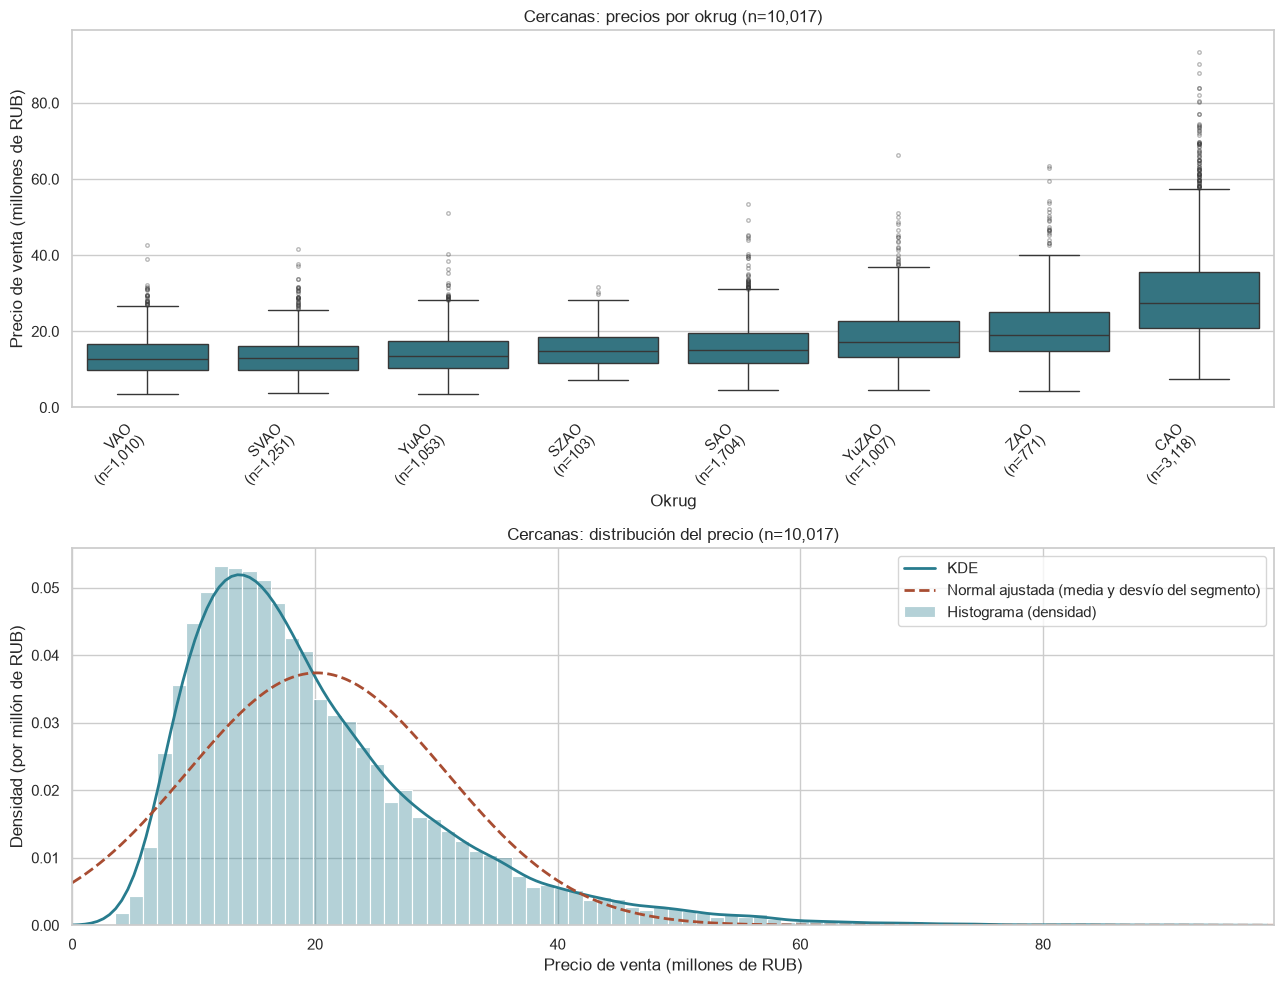

In [12]:
datos_cercanas = train_distancia.loc[train_distancia.segmento_distancia.eq("Cercanas")].copy()
metricas_distancia_train["Cercanas"] = metricas_segmento_distancia(datos_cercanas)
tabla_individual = metricas_distancia_train["Cercanas"].rename_axis("Métrica").reset_index(name="Valor")
tabla_individual["Valor"] = [formato_numero_distancia(valor, 0 if metrica == "Cantidad" else 3)
                              for metrica, valor in zip(tabla_individual["Métrica"], tabla_individual["Valor"])]
tablas_markdown_distancia_train["Cercanas"] = tabla_markdown_distancia(tabla_individual)
graficar_segmento_distancia(datos_cercanas, "Cercanas")

| Métrica | Valor |
| --- | --- |
| Cantidad | 10.017 |
| Distancia mínima (km) | 0,070 |
| Distancia máxima (km) | 9,030 |
| Distancia mediana (km) | 5,910 |
| Precio medio (millones RUB) | 20,133 |
| Precio mediano (millones RUB) | 17,478 |
| Desvío del precio (millones RUB) | 10,673 |
| Precio mínimo (millones RUB) | 3,612 |
| Precio máximo (millones RUB) | 93,437 |
| Q1 del precio (millones RUB) | 12,559 |
| Q3 del precio (millones RUB) | 24,895 |
| Asimetría | 1,551 |
| Curtosis excesiva | 3,450 |

## 4. Intermedias

Solo observaciones de entrenamiento. Los okrugs se ordenan por su mediana dentro de este segmento; se mantienen los valores extremos.

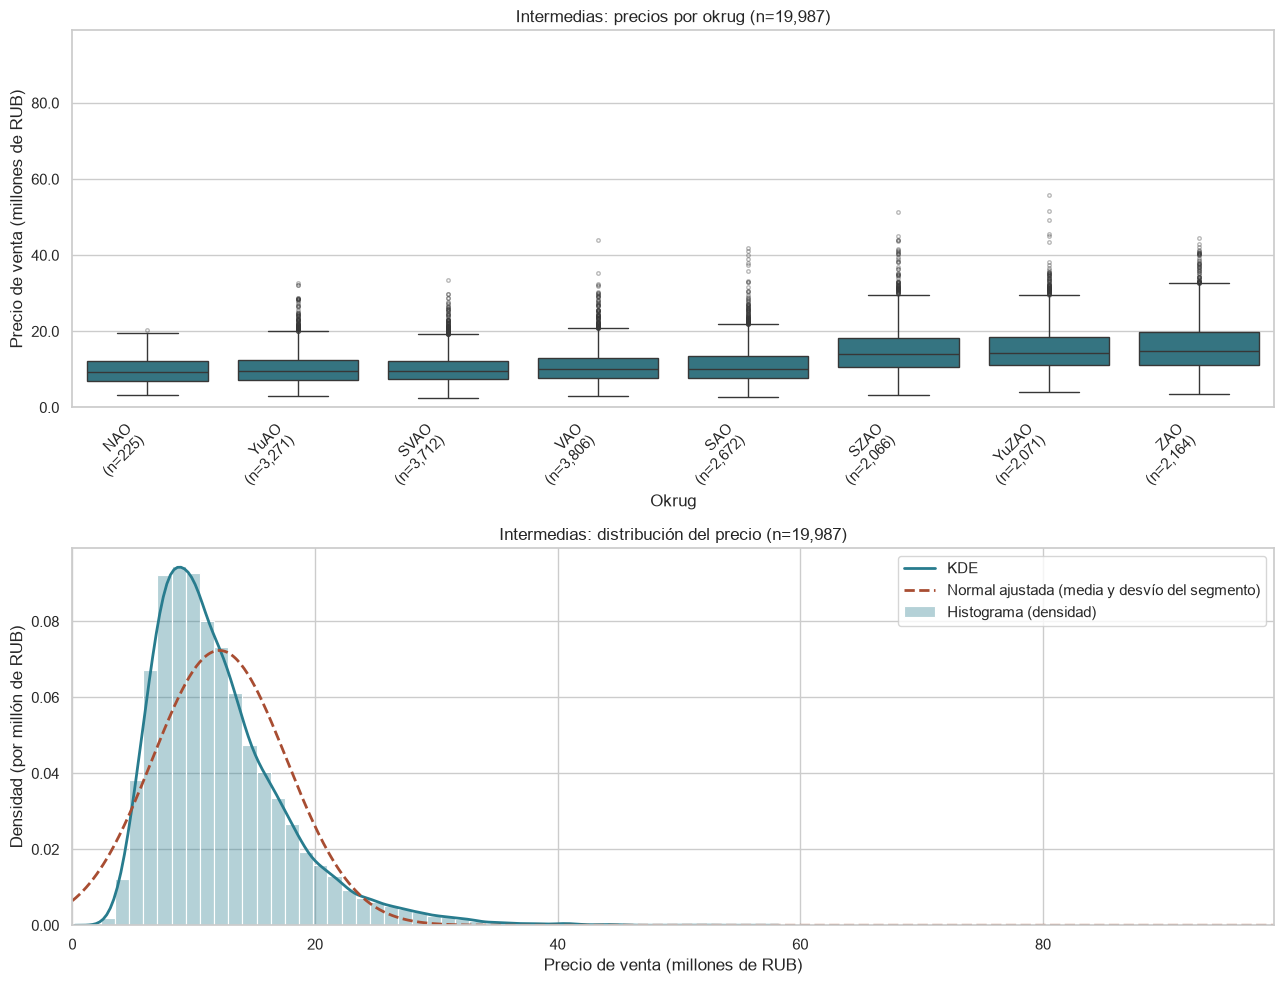

In [13]:
datos_intermedias = train_distancia.loc[train_distancia.segmento_distancia.eq("Intermedias")].copy()
metricas_distancia_train["Intermedias"] = metricas_segmento_distancia(datos_intermedias)
tabla_individual = metricas_distancia_train["Intermedias"].rename_axis("Métrica").reset_index(name="Valor")
tabla_individual["Valor"] = [formato_numero_distancia(valor, 0 if metrica == "Cantidad" else 3)
                              for metrica, valor in zip(tabla_individual["Métrica"], tabla_individual["Valor"])]
tablas_markdown_distancia_train["Intermedias"] = tabla_markdown_distancia(tabla_individual)
graficar_segmento_distancia(datos_intermedias, "Intermedias")

| Métrica | Valor |
| --- | --- |
| Cantidad | 19.987 |
| Distancia mínima (km) | 9,040 |
| Distancia máxima (km) | 18,030 |
| Distancia mediana (km) | 13,230 |
| Precio medio (millones RUB) | 12,119 |
| Precio mediano (millones RUB) | 10,907 |
| Desvío del precio (millones RUB) | 5,515 |
| Precio mínimo (millones RUB) | 2,491 |
| Precio máximo (millones RUB) | 55,927 |
| Q1 del precio (millones RUB) | 8,210 |
| Q3 del precio (millones RUB) | 14,703 |
| Asimetría | 1,480 |
| Curtosis excesiva | 3,480 |

## 5. Lejanas

Solo observaciones de entrenamiento. Los okrugs se ordenan por su mediana dentro de este segmento; se mantienen los valores extremos.

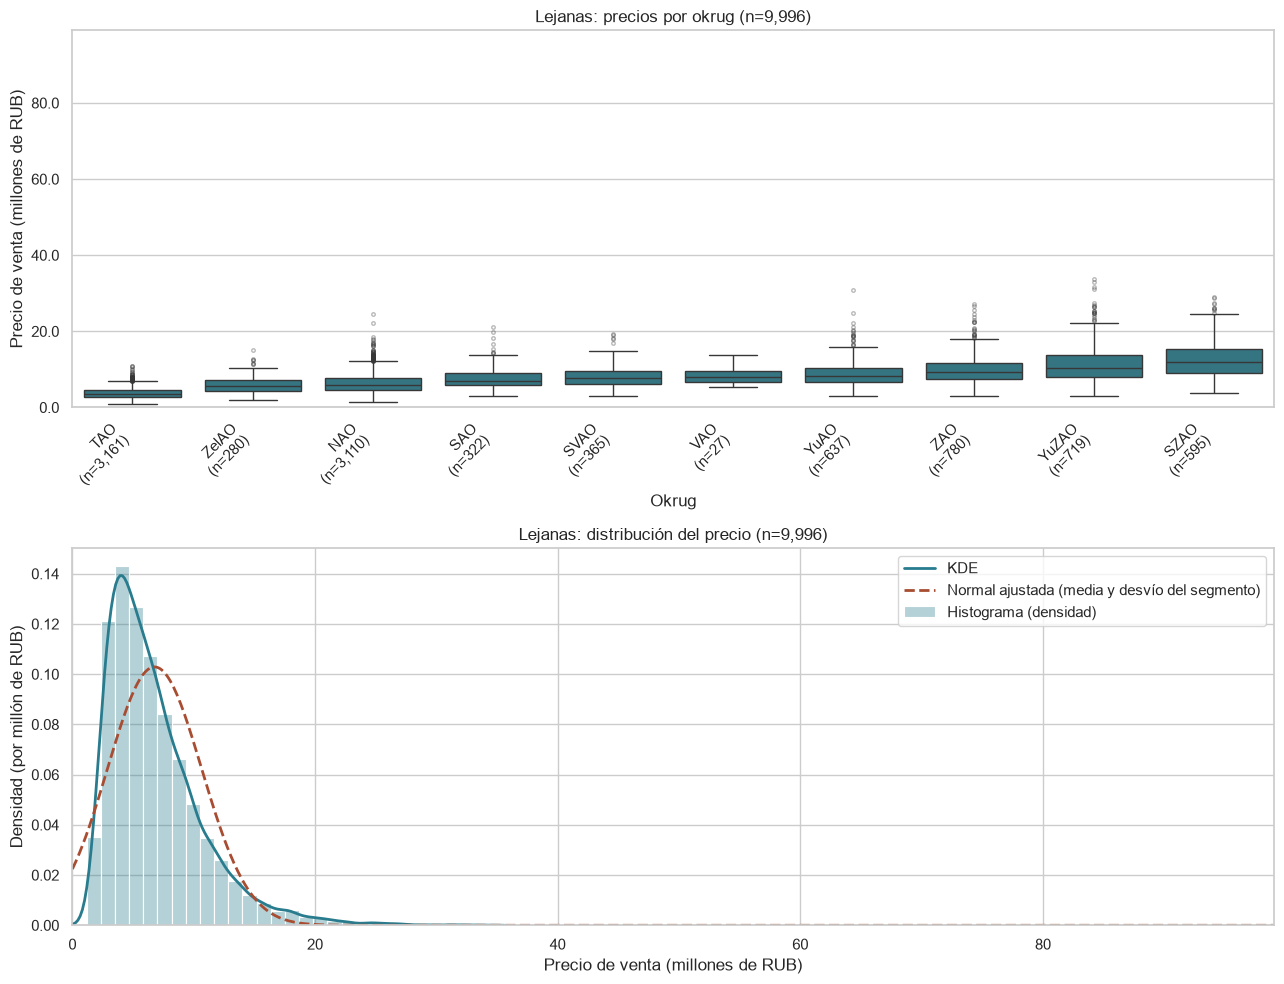

In [14]:
datos_lejanas = train_distancia.loc[train_distancia.segmento_distancia.eq("Lejanas")].copy()
metricas_distancia_train["Lejanas"] = metricas_segmento_distancia(datos_lejanas)
tabla_individual = metricas_distancia_train["Lejanas"].rename_axis("Métrica").reset_index(name="Valor")
tabla_individual["Valor"] = [formato_numero_distancia(valor, 0 if metrica == "Cantidad" else 3)
                              for metrica, valor in zip(tabla_individual["Métrica"], tabla_individual["Valor"])]
tablas_markdown_distancia_train["Lejanas"] = tabla_markdown_distancia(tabla_individual)
graficar_segmento_distancia(datos_lejanas, "Lejanas")

| Métrica | Valor |
| --- | --- |
| Cantidad | 9.996 |
| Distancia mínima (km) | 18,040 |
| Distancia máxima (km) | 70,400 |
| Distancia mediana (km) | 27,020 |
| Precio medio (millones RUB) | 6,772 |
| Precio mediano (millones RUB) | 5,857 |
| Desvío del precio (millones RUB) | 3,878 |
| Precio mínimo (millones RUB) | 1,019 |
| Precio máximo (millones RUB) | 33,742 |
| Q1 del precio (millones RUB) | 3,951 |
| Q3 del precio (millones RUB) | 8,572 |
| Asimetría | 1,571 |
| Curtosis excesiva | 3,707 |

## 6. Comparación de los segmentos de entrenamiento

Precios en millones de RUB y distancias en kilómetros. La desviación estándar es muestral; asimetría y curtosis excesiva son adimensionales. La curtosis usa la referencia de Fisher (normal = 0). La tabla reúne las métricas de los tres bloques anteriores; test continúa reservado y sin segmentar.

In [15]:
comparacion_distancia_train = pd.DataFrame(metricas_distancia_train).T.reindex(orden_distancia)
comparacion_distancia_train.index.name = "Segmento"
markdown_comparacion_distancia_train = tabla_markdown_distancia(comparacion_distancia_train.reset_index())
assert comparacion_distancia_train.Cantidad.sum() == 40_000
assert len(train_distancia) + len(test_distancia) == len(df_ampliado_base)
pd.testing.assert_frame_equal(train_distancia.drop(columns=["fecha_publicacion", "segmento_distancia"]).sort_index(),
                              df_ampliado_base.loc[train_distancia.index].sort_index())
pd.testing.assert_frame_equal(test_distancia.drop(columns=["fecha_publicacion"]).sort_index(),
                              df_ampliado_base.loc[test_distancia.index].sort_index())
assert "segmento_distancia" not in test_distancia
assert "segmento_distancia" not in df_final
assert "segmento_distancia" not in df_ampliado_base

| Segmento | Cantidad | Distancia mínima (km) | Distancia máxima (km) | Distancia mediana (km) | Precio medio (millones RUB) | Precio mediano (millones RUB) | Desvío del precio (millones RUB) | Precio mínimo (millones RUB) | Precio máximo (millones RUB) | Q1 del precio (millones RUB) | Q3 del precio (millones RUB) | Asimetría | Curtosis excesiva |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cercanas | 10.017 | 0,070 | 9,030 | 5,910 | 20,133 | 17,478 | 10,673 | 3,612 | 93,437 | 12,559 | 24,895 | 1,551 | 3,450 |
| Intermedias | 19.987 | 9,040 | 18,030 | 13,230 | 12,119 | 10,907 | 5,515 | 2,491 | 55,927 | 8,210 | 14,703 | 1,480 | 3,480 |
| Lejanas | 9.996 | 18,040 | 70,400 | 27,020 | 6,772 | 5,857 | 3,878 | 1,019 | 33,742 | 3,951 | 8,572 | 1,571 | 3,707 |

## 7. Transformación Box-Cox por segmento

Se utiliza únicamente `train_distancia`, con las 40.000 filas y los segmentos ya definidos. Cada segmento recibe un λ propio, estimado por máxima verosimilitud sobre su `price_rub` original en RUB, sin desplazar ni estandarizar. `train_boxcox_distancia` conserva el precio original y agrega `boxcox_price_rub`; los DataFrames anteriores y test permanecen intactos. No se recalculan los cuartiles de distancia ni se excluyen registros.

`lambdas_boxcox_distancia` asocia cada segmento con su λ. `parametros_boxcox_distancia` conserva esos parámetros junto con los límites de distancia para aplicar posteriormente a prueba, sin volver a ajustarlos. El λ global de los análisis anteriores no interviene en esta etapa.

In [16]:
from scipy.stats import boxcox, norm, probplot

train_boxcox_distancia = train_distancia.copy(deep=True)
if "boxcox_price_rub" in train_boxcox_distancia:
    raise ValueError("La entrada debe contener los precios originales, sin una transformación Box-Cox previa.")
train_boxcox_distancia["boxcox_price_rub"] = np.nan
lambdas_boxcox_distancia = {}
metricas_boxcox_distancia = []
filas_resumen_boxcox_distancia = []

def resumen_boxcox_distancia(serie):
    return {"Cantidad": int(serie.count()), "Media": serie.mean(), "Mediana": serie.median(),
            "Desviación estándar": serie.std(ddof=1), "Asimetría": serie.skew(),
            "Curtosis excesiva": serie.kurt()}

for segmento in orden_distancia:
    mascara = train_boxcox_distancia.segmento_distancia.eq(segmento)
    precios_segmento = train_boxcox_distancia.loc[mascara, "price_rub"]
    if not (np.isfinite(precios_segmento) & precios_segmento.gt(0)).all() or precios_segmento.nunique() < 2:
        raise ValueError(f"{segmento}: Box-Cox requiere precios positivos, finitos y no constantes.")
    transformados, lambda_segmento = boxcox(precios_segmento.to_numpy(dtype=float))
    lambdas_boxcox_distancia[segmento] = float(lambda_segmento)
    train_boxcox_distancia.loc[mascara, "boxcox_price_rub"] = transformados
    metricas_originales = resumen_boxcox_distancia(precios_segmento)
    metricas_transformadas = resumen_boxcox_distancia(pd.Series(transformados))
    metricas_boxcox_distancia.append({"Segmento": segmento, "λ Box-Cox": lambda_segmento,
        "Asimetría original": metricas_originales["Asimetría"],
        "Asimetría Box-Cox": metricas_transformadas["Asimetría"],
        "Curtosis original": metricas_originales["Curtosis excesiva"],
        "Curtosis Box-Cox": metricas_transformadas["Curtosis excesiva"]})
    for escala, resumen in [("Original (RUB)", metricas_originales), ("Box-Cox (λ del segmento)", metricas_transformadas)]:
        filas_resumen_boxcox_distancia.append({"Segmento": segmento, "Escala": escala,
            **{m: resumen[m] for m in ["Cantidad", "Media", "Mediana", "Desviación estándar"]}})

comparacion_boxcox_distancia = pd.DataFrame(metricas_boxcox_distancia)
resumen_escalas_boxcox_distancia = pd.DataFrame(filas_resumen_boxcox_distancia)
parametros_boxcox_distancia = {"limites_distancia_km": limites_distancia_train.copy(),
                              "lambda_por_segmento": lambdas_boxcox_distancia.copy()}
markdown_forma_boxcox_distancia = tabla_markdown_distancia(comparacion_boxcox_distancia)
markdown_escalas_boxcox_distancia = tabla_markdown_distancia(resumen_escalas_boxcox_distancia)

assert len(train_boxcox_distancia) == 40_000
assert train_boxcox_distancia.index.equals(train_distancia.index)
assert train_boxcox_distancia.id.is_unique
pd.testing.assert_frame_equal(train_boxcox_distancia[train_distancia.columns], train_distancia)
assert np.isfinite(train_boxcox_distancia.boxcox_price_rub).all()
assert set(lambdas_boxcox_distancia) == set(orden_distancia)
assert parametros_boxcox_distancia["limites_distancia_km"] == limites_distancia_train
assert "boxcox_price_rub" not in test_distancia
assert "segmento_distancia" not in test_distancia

**Comparación de la forma y λ estimados por segmento**

| Segmento | λ Box-Cox | Asimetría original | Asimetría Box-Cox | Curtosis original | Curtosis Box-Cox |
| --- | --- | --- | --- | --- | --- |
| Cercanas | -0,095 | 1,551 | 0,004 | 3,450 | -0,222 |
| Intermedias | -0,112 | 1,480 | 0,002 | 3,480 | -0,120 |
| Lejanas | -0,032 | 1,571 | 0,002 | 3,707 | -0,358 |

**Ubicación y dispersión antes y después**

Media, mediana y desvío están en RUB para las filas originales y en la escala Box-Cox propia del segmento para las transformadas.

| Segmento | Escala | Cantidad | Media | Mediana | Desviación estándar |
| --- | --- | --- | --- | --- | --- |
| Cercanas | Original (RUB) | 10.017 | 20.133.052,311 | 17.478.000,000 | 10.673.041,611 |
| Cercanas | Box-Cox (λ del segmento) | 10.017 | 8,379 | 8,378 | 0,101 |
| Intermedias | Original (RUB) | 19.987 | 12.118.573,223 | 10.907.000,000 | 5.514.604,904 |
| Intermedias | Box-Cox (λ del segmento) | 19.987 | 7,477 | 7,477 | 0,069 |
| Lejanas | Original (RUB) | 9.996 | 6.772.333,533 | 5.857.000,000 | 3.877.883,263 |
| Lejanas | Box-Cox (λ del segmento) | 9.996 | 12,276 | 12,279 | 0,329 |

**Distribuciones transformadas.** Cada panel utiliza su propia escala horizontal Box-Cox. El histograma representa densidad y la normal de referencia se calcula con la media y el desvío muestral del segmento. Los títulos muestran cantidad, λ, asimetría (A) y curtosis excesiva (K). Estos indicadores describen la forma sin demostrar normalidad.

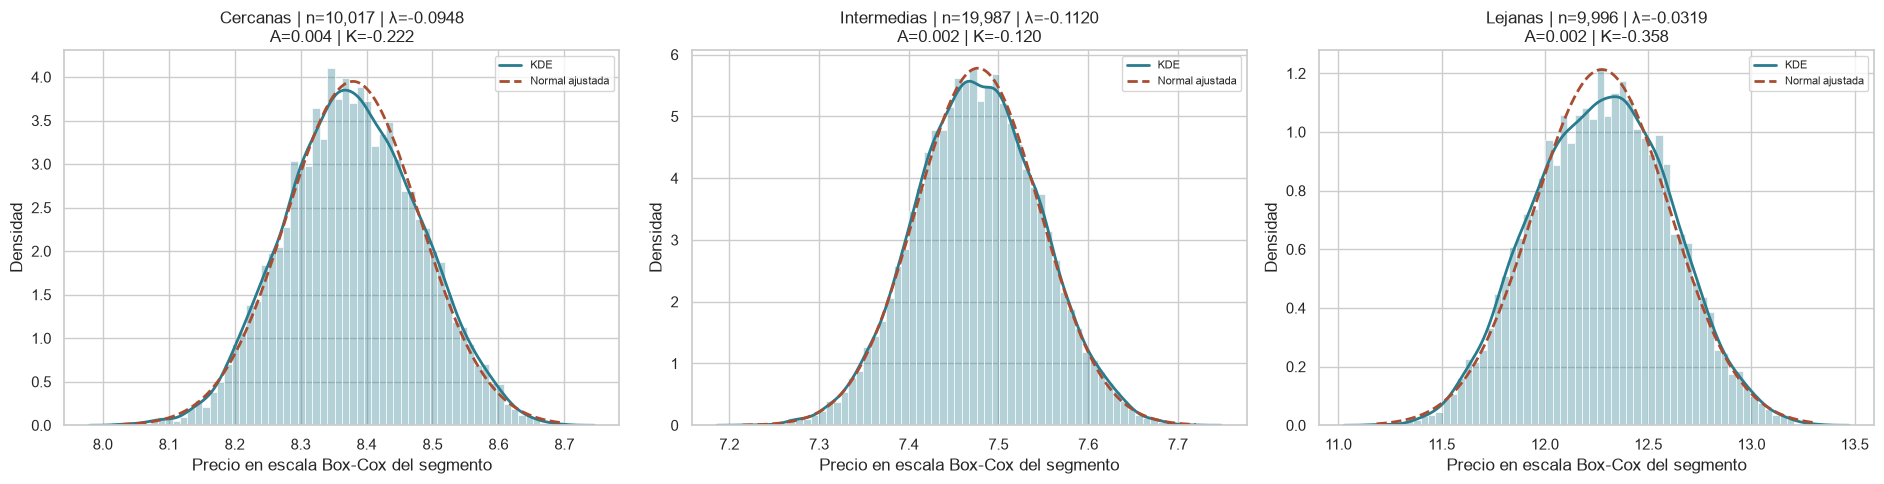

In [17]:
def graficar_densidad_boxcox_distancia(ax, valores, titulo, etiqueta_x):
    valores = pd.Series(valores)
    media, desvio = valores.mean(), valores.std(ddof=1)
    x = np.linspace(min(valores.min(), media - 3 * desvio),
                    max(valores.max(), media + 3 * desvio), 600)
    sns.histplot(x=valores, bins=60, stat="density", color=COLOR, alpha=0.35, ax=ax)
    sns.kdeplot(x=valores, color=COLOR, linewidth=2, label="KDE", ax=ax)
    ax.plot(x, norm.pdf(x, media, desvio), color="#A84D32", linestyle="--", linewidth=2,
            label="Normal ajustada")
    ax.set(title=titulo, xlabel=etiqueta_x, ylabel="Densidad")
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharex=False)
for ax, segmento in zip(axes, orden_distancia):
    valores = train_boxcox_distancia.loc[train_boxcox_distancia.segmento_distancia.eq(segmento), "boxcox_price_rub"]
    titulo = (f"{segmento} | n={len(valores):,} | λ={lambdas_boxcox_distancia[segmento]:.4f}\n"
              f"A={valores.skew():.3f} | K={valores.kurt():.3f}")
    graficar_densidad_boxcox_distancia(ax, valores, titulo, "Precio en escala Box-Cox del segmento")
plt.tight_layout()
plt.show()

**Q-Q plots frente a una normal.** Se comparan los cuantiles ordenados transformados con los cuantiles de una normal estándar. La línea se ajusta por mínimos cuadrados (`probplot`). La proximidad a una recta indica compatibilidad visual; las desviaciones de los extremos permiten examinar las colas.

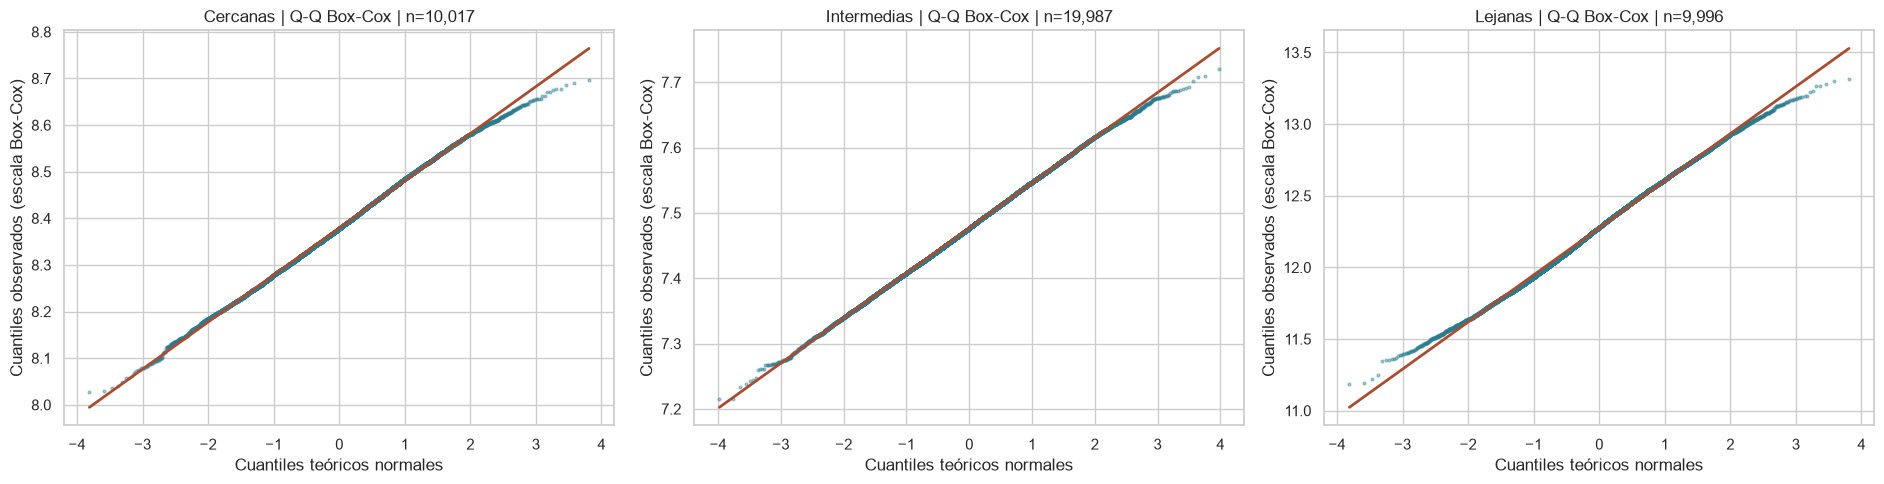

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, segmento in zip(axes, orden_distancia):
    valores = train_boxcox_distancia.loc[train_boxcox_distancia.segmento_distancia.eq(segmento), "boxcox_price_rub"]
    probplot(valores, dist="norm", plot=ax)
    ax.get_lines()[0].set(color=COLOR, markersize=2, alpha=0.4)
    ax.get_lines()[1].set(color="#A84D32", linewidth=2)
    ax.set(title=f"{segmento} | Q-Q Box-Cox | n={len(valores):,}",
           xlabel="Cuantiles teóricos normales", ylabel="Cuantiles observados (escala Box-Cox)")
plt.tight_layout()
plt.show()

**Comparación antes y después.** Una fila por segmento: precio original expresado en millones de RUB a la izquierda y escala Box-Cox a la derecha. El cambio de unidades del gráfico original no modifica `price_rub`. Las escalas transformadas dependen de cada λ, por lo que sus medias y desvíos no se comparan directamente entre grupos ni con RUB.

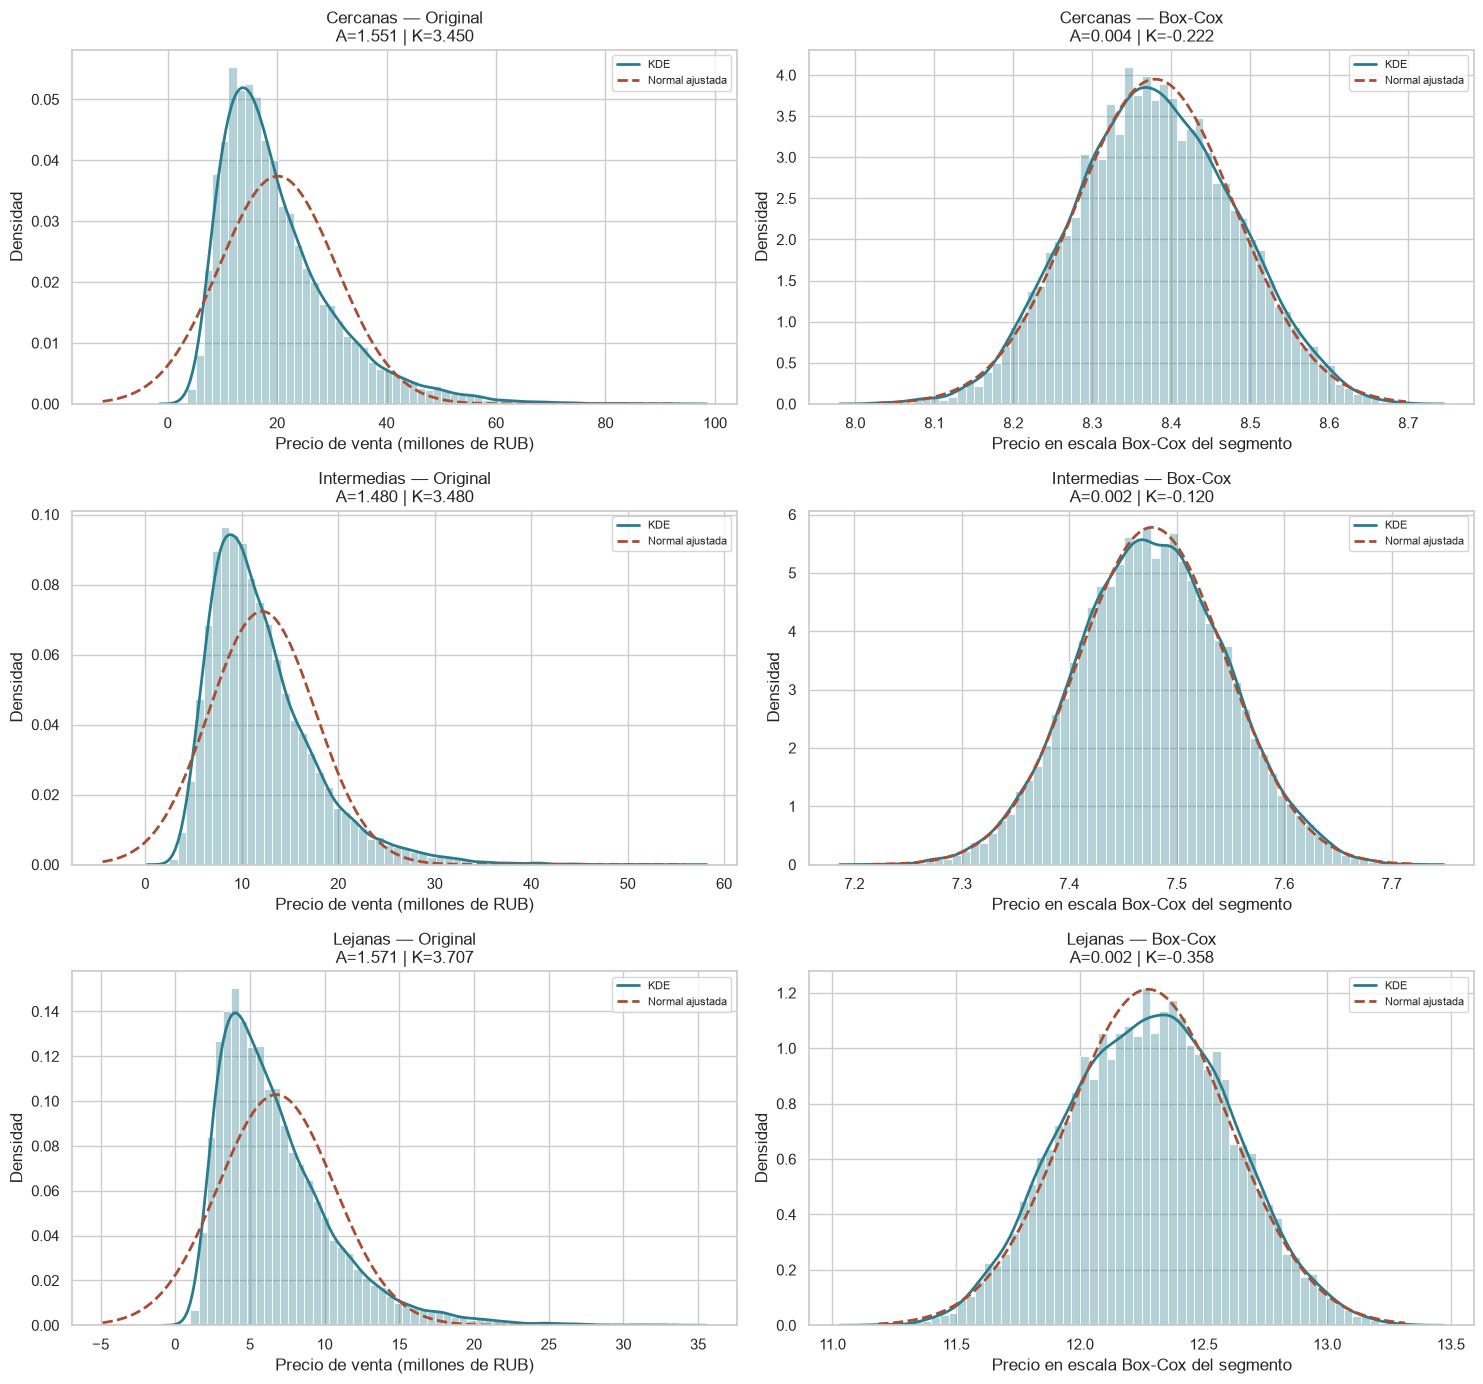

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14), sharex=False)
for fila, segmento in enumerate(orden_distancia):
    datos = train_boxcox_distancia.loc[train_boxcox_distancia.segmento_distancia.eq(segmento)]
    for columna, valores, escala, etiqueta in [
        (0, datos.price_rub / 1e6, "Original", "Precio de venta (millones de RUB)"),
        (1, datos.boxcox_price_rub, "Box-Cox", "Precio en escala Box-Cox del segmento")]:
        titulo = f"{segmento} — {escala}\nA={valores.skew():.3f} | K={valores.kurt():.3f}"
        graficar_densidad_boxcox_distancia(axes[fila, columna], valores, titulo, etiqueta)
plt.tight_layout()
plt.show()

## 8. Box-Cox en cuatro segmentos de distancia (solo entrenamiento)

Los cuartiles Q1, Q2 y Q3 se estiman exclusivamente con las 40.000 filas de `train_distancia`. Los intervalos son [mínimo, Q1], (Q1, Q2], (Q2, Q3] y (Q3, máximo]; los empates quedan juntos y pueden producir tamaños distintos. Se trabaja sobre `train_boxcox_cuartiles`, sin alterar los tres segmentos anteriores. Cada λ se ajusta al precio original positivo en RUB. La curtosis es excesiva de Fisher (normal = 0); cada panel tiene su propia escala Box-Cox y la normal ajustada es solo una referencia visual.

,Rango (km),Cantidad,λ,Asimetría antes,Asimetría después,Curtosis antes,Curtosis después
Segmento,,,,,,,
S1,"[0.070, 9.030]","10,017",-0.095,1.551,0.004,3.450,-0.222
S2,"(9.030, 13.230]","10,003",-0.076,1.336,0.002,2.745,-0.174
S3,"(13.230, 18.030]","9,984",-0.158,1.672,0.000,4.867,-0.004
S4,"(18.030, 70.400]","9,996",-0.032,1.571,0.002,3.707,-0.358


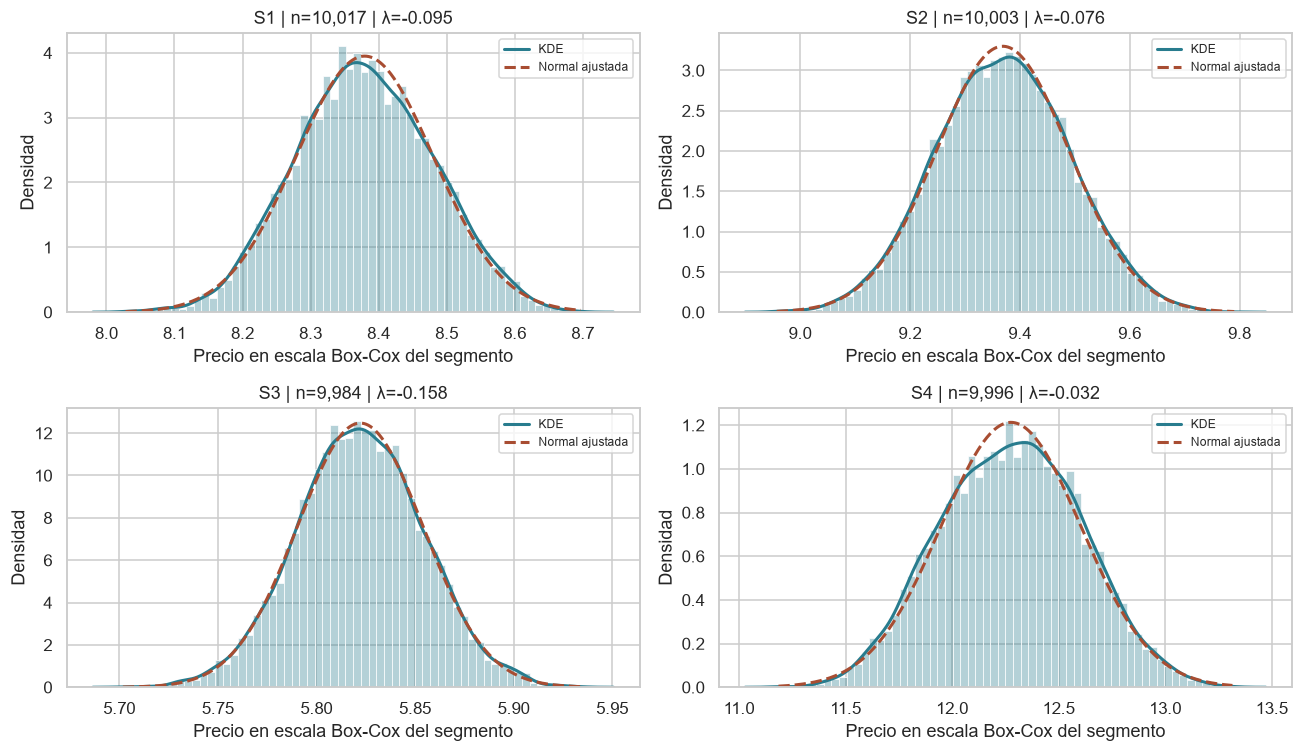

In [1]:
train_boxcox_cuartiles = train_distancia.copy(deep=True)
assert len(train_boxcox_cuartiles) == 40_000
distancias_cuartiles = train_boxcox_cuartiles.to_center_km
if not (np.isfinite(distancias_cuartiles) & distancias_cuartiles.ge(0)).all():
    raise ValueError("Las distancias deben ser finitas y no negativas.")
q1_cuartiles, q2_cuartiles, q3_cuartiles = distancias_cuartiles.quantile([0.25, 0.50, 0.75])
if not q1_cuartiles < q2_cuartiles < q3_cuartiles:
    raise ValueError("Los cuartiles no permiten cuatro intervalos distintos.")
orden_cuartiles = ["S1", "S2", "S3", "S4"]
train_boxcox_cuartiles["segmento_cuartil"] = pd.cut(
    distancias_cuartiles, [-np.inf, q1_cuartiles, q2_cuartiles, q3_cuartiles, np.inf],
    labels=orden_cuartiles, right=True)
train_boxcox_cuartiles["boxcox_price_rub"] = np.nan
lambdas_boxcox_cuartiles, filas_boxcox_cuartiles = {}, []
bordes_cuartiles = [distancias_cuartiles.min(), q1_cuartiles, q2_cuartiles,
                    q3_cuartiles, distancias_cuartiles.max()]
for i, segmento in enumerate(orden_cuartiles):
    mascara = train_boxcox_cuartiles.segmento_cuartil.eq(segmento)
    precios_cuartil = train_boxcox_cuartiles.loc[mascara, "price_rub"]
    if not (np.isfinite(precios_cuartil) & precios_cuartil.gt(0)).all() or precios_cuartil.nunique() < 2:
        raise ValueError(f"{segmento}: se requieren precios positivos, finitos y no constantes.")
    valores_cuartil, lambda_cuartil = boxcox(precios_cuartil.to_numpy(dtype=float))
    train_boxcox_cuartiles.loc[mascara, "boxcox_price_rub"] = valores_cuartil
    lambdas_boxcox_cuartiles[segmento] = float(lambda_cuartil)
    antes = resumen_boxcox_distancia(precios_cuartil)
    despues = resumen_boxcox_distancia(pd.Series(valores_cuartil))
    filas_boxcox_cuartiles.append({"Segmento": segmento,
        "Rango (km)": f"{'[' if i == 0 else '('}{bordes_cuartiles[i]:.3f}, {bordes_cuartiles[i+1]:.3f}]",
        "Cantidad": antes["Cantidad"], "λ": lambda_cuartil,
        "Asimetría antes": antes["Asimetría"], "Asimetría después": despues["Asimetría"],
        "Curtosis antes": antes["Curtosis excesiva"], "Curtosis después": despues["Curtosis excesiva"]})
resumen_boxcox_cuartiles = pd.DataFrame(filas_boxcox_cuartiles).set_index("Segmento")
parametros_boxcox_cuartiles = {"cuartiles_km": [float(q1_cuartiles), float(q2_cuartiles), float(q3_cuartiles)],
    "lambda_por_segmento": lambdas_boxcox_cuartiles.copy(), "cierre": "derecha"}
assert resumen_boxcox_cuartiles.Cantidad.sum() == 40_000
assert train_boxcox_cuartiles.segmento_cuartil.notna().all()
assert np.isfinite(train_boxcox_cuartiles.boxcox_price_rub).all()
pd.testing.assert_frame_equal(train_boxcox_cuartiles[train_distancia.columns], train_distancia)
display(resumen_boxcox_cuartiles.style.format({
    c: ("{:,.0f}" if c == "Cantidad" else "{:.3f}")
    for c in resumen_boxcox_cuartiles.select_dtypes(include="number").columns}))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, segmento in zip(axes.flat, orden_cuartiles):
    valores_cuartil = train_boxcox_cuartiles.loc[
        train_boxcox_cuartiles.segmento_cuartil.eq(segmento), "boxcox_price_rub"]
    graficar_densidad_boxcox_distancia(ax, valores_cuartil,
        f"{segmento} | n={len(valores_cuartil):,} | λ={lambdas_boxcox_cuartiles[segmento]:.3f}",
        "Precio en escala Box-Cox del segmento")
plt.tight_layout()
plt.show()

La transformación reduce la asimetría en los cuatro segmentos: pasa del intervalo 1.336–1.672 a 0.000–0.004. La curtosis excesiva posterior queda entre -0.358 y -0.004: la mayor simetría no demuestra normalidad. Los λ propios implican escalas transformadas diferentes; sus niveles no se comparan directamente entre segmentos.

### Distritos por segmento

Cada celda del cruce muestra cantidad y porcentaje sobre **todas las propiedades del distrito en entrenamiento** (cada fila suma 100 %). Se conservan los conteos y porcentajes completos en DataFrames; solo se muestra el cruce de distritos presentes en dos o más segmentos. `__FALTANTE__`, si existe, representa ausencia de información y no un distrito geográfico.

In [2]:
conteos_distritos_cuartiles = pd.crosstab(
    train_boxcox_cuartiles.district.fillna("__FALTANTE__"),
    train_boxcox_cuartiles.segmento_cuartil, dropna=False).reindex(columns=orden_cuartiles, fill_value=0)
porcentajes_distritos_cuartiles = conteos_distritos_cuartiles.div(
    conteos_distritos_cuartiles.sum(axis=1), axis=0) * 100
presencia_distritos_cuartiles = conteos_distritos_cuartiles.gt(0)
distritos_por_cuartil = pd.DataFrame({"Segmento": orden_cuartiles,
    "Distritos": [", ".join(map(str, presencia_distritos_cuartiles.index[
        presencia_distritos_cuartiles[s]])) for s in orden_cuartiles]}).set_index("Segmento")
mascara_distritos_repetidos = presencia_distritos_cuartiles.sum(axis=1).ge(2)
cruce_distritos_repetidos = conteos_distritos_cuartiles.loc[mascara_distritos_repetidos].copy().astype(str)
for s in orden_cuartiles:
    cruce_distritos_repetidos[s] = [f"{n:,} ({p:.1f} %)" for n, p in zip(
        conteos_distritos_cuartiles.loc[mascara_distritos_repetidos, s],
        porcentajes_distritos_cuartiles.loc[mascara_distritos_repetidos, s])]
assert conteos_distritos_cuartiles.to_numpy().sum() == 40_000
assert np.allclose(porcentajes_distritos_cuartiles.sum(axis=1), 100)
display(distritos_por_cuartil.style.set_properties(**{"white-space": "normal", "text-align": "left"}))
display(cruce_distritos_repetidos.style.set_table_attributes('style="display:block;max-height:420px;overflow:auto"').set_caption("Cantidad (% del total del distrito en entrenamiento)"))

,Distritos
Segmento,
S1,"Aeroport, Akademichesky, Alekseevsky, Arbat, Basmanny, Begovoy, Bogorodskoye, Butyrsky, Chertanovo Severnoye, Cheryomushki, Danilovsky, Donskoy, Dorogomilovo, Fili-Davydkovo, Filyovsky Park, Gagarinsky, Golovinsky, Izmaylovo, Khamovniki, Khoroshyovo-Mnyovniki, Khoroshyovsky, Koptevo, Kotlovka, Krasnoselsky, Kuntsevo, Lomonosovsky, Marfino, Maryina Roshcha, Meshchansky, Metrogorodok, Moskvorechye-Saburovo, Nagatino-Sadovniki, Nagatinsky Zaton, Nagorny, Novogireyevo, Obruchevsky, Ochakovo-Matveyevskoye, Ostankinsky, Otradnoye, Perovo, Preobrazhenskoye, Presnensky, Prospekt Vernadskogo, Ramenki, Rostokino, Savyolovsky, Shchukino, Sokol, Sokolinaya Gora, Sokolniki, Sviblovo, Tagansky, Timiryazevsky, Tverskoy, Veshnyaki, Voykovsky, Yakimanka, Zamoskvorechye, Zyuzino"
S2,"Aeroport, Akademichesky, Alekseevsky, Altufyevsky, Babushkinsky, Begovoy, Beskudnikovsky, Bibirevo, Bogorodskoye, Brateyevo, Butyrsky, Chertanovo Severnoye, Chertanovo Tsentralnoye, Cheryomushki, Dmitrovsky, Fili-Davydkovo, Filyovsky Park, Gagarinsky, Golovinsky, Golyanovo, Ivanovskoye, Izmaylovo, Khoroshyovo-Mnyovniki, Khoroshyovsky, Khovrino, Konkovo, Koptevo, Kosino-Ukhtomsky, Kotlovka, Krylatskoye, Kuntsevo, Levoberezhny, Lianozovo, Lomonosovsky, Losinoostrovsky, Marfino, Metrogorodok, Moskvorechye-Saburovo, Mozhaysky, Nagatino-Sadovniki, Nagatinsky Zaton, Nagorny, Novogireyevo, Novokosino, Obruchevsky, Ochakovo-Matveyevskoye, Orekhovo-Borisovo Severnoye, Orekhovo-Borisovo Yuzhnoye, Ostankinsky, Otradnoye, Perovo, Pokrovskoye-Streshnevo, Preobrazhenskoye, Prospekt Vernadskogo, Ramenki, Rostokino, Severnoye Izmaylovo, Severnoye Medvedkovo, Severnoye Tushino, Shchukino, Sokol, Sokolinaya Gora, Strogino, Sviblovo, Timiryazevsky, Troparyovo-Nikulino, Tsaritsyno, Tyoply Stan, Veshnyaki, Vostochnoye Izmaylovo, Vostochny, Voykovsky, Yaroslavsky, Yasenevo, Yuzhnoye Medvedkovo, Yuzhnoye Tushino, Zapadnoye Degunino, Zyablikovo, Zyuzino"
S3,"Altufyevsky, Babushkinsky, Beskudnikovsky, Bibirevo, Biryulyovo Vostochnoye, Biryulyovo Zapadnoye, Brateyevo, Chertanovo Severnoye, Chertanovo Tsentralnoye, Chertanovo Yuzhnoye, Dmitrovsky, Golovinsky, Golyanovo, Ivanovskoye, Izmaylovo, Khovrino, Konkovo, Koptevo, Kosino-Ukhtomsky, Krylatskoye, Kuntsevo, Kurkino, Levoberezhny, Lianozovo, Losinoostrovsky, Marfino, Metrogorodok, Mitino, Moskvorechye-Saburovo, Mosrentgen, Mozhaysky, Nagorny, Novo-Peredelkino, Novogireyevo, Novokosino, Obruchevsky, Ochakovo-Matveyevskoye, Orekhovo-Borisovo Severnoye, Orekhovo-Borisovo Yuzhnoye, Otradnoye, Perovo, Pokrovskoye-Streshnevo, Prospekt Vernadskogo, Rostokino, Severnoye Butovo, Severnoye Izmaylovo, Severnoye Medvedkovo, Severnoye Tushino, Severny, Shchukino, Sokol, Solntsevo, Strogino, Sviblovo, Troparyovo-Nikulino, Tsaritsyno, Tyoply Stan, Veshnyaki, Vostochnoye Izmaylovo, Vostochny, Voykovsky, Yaroslavsky, Yasenevo, Yuzhnoye Medvedkovo, Yuzhnoye Tushino, Zapadnoye Degunino, Zyablikovo, Zyuzino"
S4,"Altufyevsky, Bibirevo, Biryulyovo Vostochnoye, Biryulyovo Zapadnoye, Brateyevo, Chertanovo Yuzhnoye, Desyonovskoye, Dmitrovsky, Filimonkovskoye, Khovrino, Kievsky, Klyonovskoye, Kokoshkino, Konkovo, Kosino-Ukhtomsky, Krasnopakhorskoye, Kurkino, Levoberezhny, Lianozovo, Losinoostrovsky, Marushkinskoye, Mikhaylovo-Yartsevskoye, Mitino, Molzhaninovsky, Moskovsky, Mosrentgen, Novo-Peredelkino, Novofyodorovskoye, Novokosino, Orekhovo-Borisovo Severnoye, Orekhovo-Borisovo Yuzhnoye, Pervomayskoye, Rogovskoye, Ryazanovskoye, Severnoye Butovo, Severnoye Tushino, Severny, Shchapovskoye, Shcherbinka, Solntsevo, Sosenskoye, Strogino, Troitsk, Tsaritsyno, Tyoply Stan, Vnukovo, Vnukovskoye, Voronovskoye, Voskresenskoye, Vostochny, Yaroslavsky, Yasenevo, Yuzhnoye Butovo, Zelenograd, Zyablikovo"


segmento_cuartil,S1,S2,S3,S4
district,,,,
Aeroport,249 (81.1 %),58 (18.9 %),0 (0.0 %),0 (0.0 %)
Akademichesky,259 (76.9 %),78 (23.1 %),0 (0.0 %),0 (0.0 %)
Alekseevsky,321 (97.3 %),9 (2.7 %),0 (0.0 %),0 (0.0 %)
Altufyevsky,0 (0.0 %),22 (6.6 %),305 (91.9 %),5 (1.5 %)
Babushkinsky,0 (0.0 %),186 (60.6 %),121 (39.4 %),0 (0.0 %)
Begovoy,351 (99.2 %),3 (0.8 %),0 (0.0 %),0 (0.0 %)
Beskudnikovsky,0 (0.0 %),106 (36.8 %),182 (63.2 %),0 (0.0 %)
Bibirevo,0 (0.0 %),52 (16.0 %),271 (83.6 %),1 (0.3 %)
Biryulyovo Vostochnoye,0 (0.0 %),0 (0.0 %),67 (19.9 %),269 (80.1 %)


**Conclusión.** En entrenamiento, 89 de los 129 distritos aparecen en dos o más segmentos (el listado completo figura en el cruce), entre ellos Aeroport, Akademichesky, Kuntsevo, Mitino y Yasenevo. La distancia al centro diferencia franjas de cercanía, pero no separa claramente los distritos administrativos: un mismo distrito puede atravesar varios cortes y una franja reúne ubicaciones en distintas direcciones. Por ello, la distancia aporta una diferenciación radial útil, aunque insuficiente para identificar una zona geográfica única.